# Estimacion del riesgo de paralizacion de obras publicas: proyecto final

Notebook consolidado para el proyecto final del curso de Modelos Estadisticos para el Analisis de Datos (Statistical Learning), siguiendo la estructura requerida en `mead_project/instrucciones.md` (incluye comparacion de 5+ modelos estadisticos, exigida en la seccion `Marco Teorico` del informe). Consolida y depura el trabajo previo de [`notebooks/02_eda.ipynb`](../notebooks/02_eda.ipynb), [`notebooks/03_feature_engineering.ipynb`](../notebooks/03_feature_engineering.ipynb) / [`03_04_feature_engineering_target_woe_encoding_igeip_inco.ipynb`](../notebooks/03_04_feature_engineering_target_woe_encoding_igeip_inco.ipynb) y [`04_modeling.ipynb`](../notebooks/04_modeling.ipynb). Tambien retoma el patron de comparacion de modelos GLM (tabla de odds ratio ordenada) de [`Laboratorio4_GLM_PCA_2026I_MIES.ipynb`](./ref_notebooks/Laboratorio4_GLM_PCA_2026I_MIES.ipynb).

**Problema**: clasificacion binaria desbalanceada (~7-10% clase positiva). `flg_opa_incumplimiento_contractual = 1` si la obra publica se paralizo por incumplimiento contractual, `0` en caso contrario. La probabilidad predicha `P(Y=1|X)` se interpreta como una medida cuantitativa de riesgo de paralizacion para priorizar el seguimiento de obras en ejecucion.

**Fuente de datos**: `data/gold/ds_op_inco_igeip.csv`, un dataset integrado (capa "gold") que enriquece la tabla original de InfObras con dos fuentes adicionales trabajadas por separado: el **INCO** (Indice de Capacidad de Gestion, `inco_2024_entidad`) y el **IGEIP** (Indice de Gestion de Inversion Publica, `igeip_sector` / `igeip_sector_ejecucion`) de la entidad/sector ejecutor. Esto reemplaza la consulta directa a PostgreSQL usada en `03_feature_engineering.ipynb` (mismo universo de datos, ya materializado con estas columnas adicionales), lo que ademas hace el notebook reproducible sin depender de una base de datos en vivo.

**Diferencia metodologica clave frente a `03`/`04`**: alli el `ColumnTransformer` (target encoding, WOE, one-hot) se ajustaba **una sola vez** sobre todo el train antes de la validacion cruzada, una fuga de datos leve entre folds. Aqui el preprocesamiento se coloca **dentro de un `Pipeline`** junto con el clasificador para `M2`/`RF`, de modo que la validacion cruzada anidada ajusta los encoders de forma independiente en cada fold — esto es lo que en el roadmap original de `03_feature_engineering.ipynb` se dejo pendiente como `M3`.

**Modelos comparados** (seccion 5): `M0` (regresion logistica base, sin penalizar ni ponderar — referencia "ingenua"), `M2` (regresion logistica penalizada Elastic Net, ponderada por clase), `RF` (Random Forest, ponderado por clase), `M4` (GLM binomial c-loglog, ponderado), `M5` (GLM binomial probit, ponderado), `M6` (GAM logit, ponderado), `M7` (GAM c-loglog, ponderado) y `M8` (GAM probit, ponderado): 8 modelos en total.

## 0. Configuracion y reproducibilidad

Se fija una semilla global (`RANDOM_STATE`) reutilizada en todo estimador con componente aleatoria (`RandomForestClassifier`, solver `saga` de `LogisticRegression`). Las particiones de validacion cruzada temporal (`TimeSeriesSplit`) son deterministas por construccion (sin shuffle): el orden temporal de los datos debe respetarse.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import Markdown, display
from statsmodels.gam.api import BSplines, GLMGam

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
sns.set_theme(style="whitegrid")

# Agregar 'src' al path para importar los modulos del proyecto
project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.eda import missing_values_report
from src.evaluation import (
    analizar_umbrales,
    graficar_calibracion_comparativa,
    graficar_umbrales,
    importancia_arbol,
    importancia_gam_statsmodels,
    importancia_glm_statsmodels,
    importancia_lineal_sklearn,
    reporte_evaluacion,
)
from src.features import build_preprocessor, columnas_sin_colinealidad


def calcular_aic_bic(log_verosimilitud, n_parametros, n_obs):
    """AIC/BIC con conteo simple de parametros (2k - 2*llf / k*ln(n) - 2*llf).

    Se evita usar las propiedades `.aic`/`.bic` nativas de `GLMGam`: para GAM
    penalizados usan "grados de libertad efectivos" (traza de la matriz
    hat penalizada) que puede volverse numericamente inestable (se observo
    un caso con el enlace logit donde el df efectivo se disparaba a >70,000
    frente a ~40 del enlace c-loglog con la misma estructura de modelo,
    pese a tener log-verosimilitudes casi identicas). El conteo simple de
    parametros es menos preciso bajo penalizacion pero es estable y
    comparable entre modelos.
    """
    aic = 2 * n_parametros - 2 * log_verosimilitud
    bic = n_parametros * np.log(n_obs) - 2 * log_verosimilitud
    return aic, bic


## 1. Carga y entendimiento de los datos

Fuente: `data/gold/ds_op_inco_igeip.csv`. Se filtra a `nivel_gobierno = 'GOBIERNO NACIONAL'` y `marco = 'INVIERTE'` para trabajar con un universo homogeneo de proyectos bajo el mismo marco de inversion publica (decision explorada en detalle en `02_eda.ipynb`).

In [2]:
TARGET = "flg_opa_incumplimiento_contractual"
DATE_COL = "fecha_inicio_obra"

gold_path = project_root / "data" / "gold" / "ds_op_inco_igeip.csv"
df_raw = pd.read_csv(gold_path, encoding="utf-8", low_memory=False)

df = df_raw[
    (df_raw["nivel_gobierno"] == "GOBIERNO NACIONAL") & (df_raw["marco"] == "INVIERTE")
].copy()

print(f"Registros cargados: {len(df_raw):,}")
print(f"Registros tras el filtro: {len(df):,}")


Registros cargados: 69,952
Registros tras el filtro: 2,646


### Resumen estadistico y distribucion del target

In [3]:
display(Markdown("**Distribucion del target (todo el universo filtrado)**"))
display(df[TARGET].value_counts(normalize=True).rename("proporcion").to_frame())

display(Markdown("**Resumen de `monto_aprobado_soles`**"))
display(df["monto_aprobado_soles"].describe().to_frame().T)


**Distribucion del target (todo el universo filtrado)**

,proporcion
flg_opa_incumplimiento_contractual,
0,0.925548
1,0.074452


**Resumen de `monto_aprobado_soles`**

,count,mean,std,min,25%,50%,75%,max
monto_aprobado_soles,2628.0,9.211674e+06,3.605973e+07,0.0,460497.69,1454460.395,5.682044e+06,685428264.0


### Variables adicionales INCO / IGEIP

`inco_2024_entidad` (Indice de Capacidad de Gestion, escala propia -no acotada a [0, 1]-, poca nulidad) e `igeip_sector` / `igeip_sector_ejecucion` (Indice de Gestion de Inversion Publica del sector, en [0, 1], con alta proporcion de nulos porque el indice IGEIP solo cubre un subconjunto de sectores/entidades). Al ser variables numericas continuas, los nulos se imputan con la **mediana** (ver seccion 3): es una imputacion robusta a outliers y, dada la alta nulidad de las columnas IGEIP, evita introducir valores extremos artificiales.

In [4]:
columnas_inco_igeip = ["inco_2024_entidad", "igeip_sector", "igeip_sector_ejecucion"]
display(df[columnas_inco_igeip].describe().T)
display(df[columnas_inco_igeip].isna().mean().rename("proporcion_nulos").to_frame())


,count,mean,std,min,25%,50%,75%,max
inco_2024_entidad,2644.0,48.578782,16.217435,8.500,40.175,53.600,60.000,86.200
igeip_sector,2135.0,0.656113,0.035094,0.417,0.656,0.659,0.683,0.739
igeip_sector_ejecucion,2135.0,0.595169,0.040858,0.400,0.573,0.586,0.626,0.702


,proporcion_nulos
inco_2024_entidad,0.000756
igeip_sector,0.193122
igeip_sector_ejecucion,0.193122


In [5]:
# Reporte de valores faltantes en las columnas relevantes para este proyecto
columnas_interes = [
    "tipo_obra_nivel_1", "tipo_obra_nivel_2", "tipo_obra_nivel_3", "departamento", "provincia",
    "codigo_entidad", "sector_entidad", "naturaleza_obra", "tipo_formato",
    "monto_aprobado_soles", "monto_aprobacion_et", "n_obras_relacionadas_proyecto",
    *columnas_inco_igeip, DATE_COL, TARGET,
]
df_reducido = df[columnas_interes].copy()
display(missing_values_report(df_reducido))


,missing_count,missing_percentage
igeip_sector,511,19.31
igeip_sector_ejecucion,511,19.31
tipo_formato,95,3.59
monto_aprobado_soles,18,0.68
monto_aprobacion_et,18,0.68
inco_2024_entidad,2,0.08
departamento,1,0.04
provincia,1,0.04


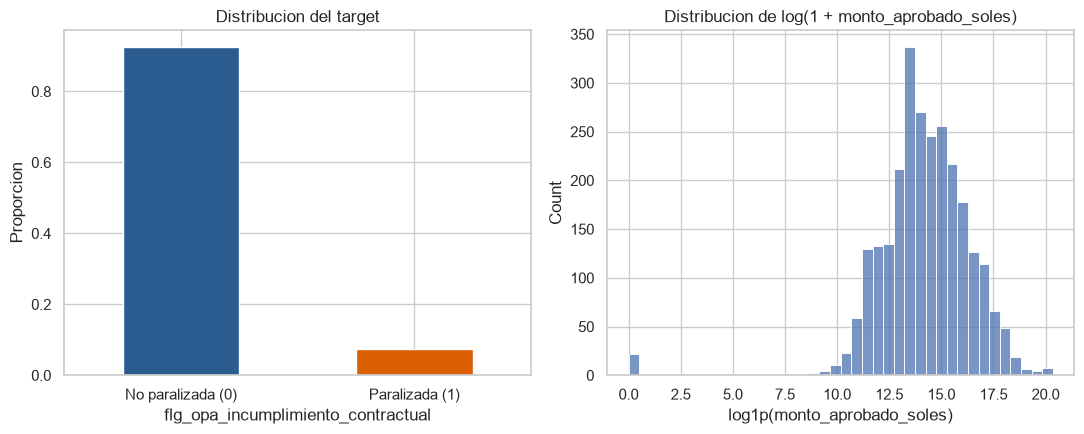

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

df[TARGET].value_counts(normalize=True).sort_index().plot(
    kind="bar", ax=axes[0], color=["#2b5c8f", "#d95f02"]
)
axes[0].set_title("Distribucion del target")
axes[0].set_xticklabels(["No paralizada (0)", "Paralizada (1)"], rotation=0)
axes[0].set_ylabel("Proporcion")

sns.histplot(np.log1p(df["monto_aprobado_soles"].dropna()), bins=40, ax=axes[1])
axes[1].set_title("Distribucion de log(1 + monto_aprobado_soles)")
axes[1].set_xlabel("log1p(monto_aprobado_soles)")

plt.tight_layout()
plt.show()


In [7]:
# Tasa de paralizacion cruda por departamento (sin ningun ajuste de train/test,
# solo para entender la relacion antes de modelar)
tasa_por_departamento = (
    df_reducido.groupby("departamento")[TARGET]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)
display(Markdown("**Tasa de paralizacion por departamento (top 10)**"))
display(tasa_por_departamento.head(10))


**Tasa de paralizacion por departamento (top 10)**

,mean,count
departamento,,
P C DEL CALLAO,0.181818,22
TUMBES,0.152778,72
MADRE DE DIOS,0.137931,29
ANCASH,0.134752,282
LA LIBERTAD,0.132979,188
JUNIN,0.098765,81
HUANCAVELICA,0.098361,61
AYACUCHO,0.090909,44
ICA,0.088889,45


### Analisis de correlacion

Correlacion de Pearson entre las variables numericas relevantes (incluyendo `log(1 + monto_aprobado_soles)` en vez del monto crudo, por su fuerte asimetria) y el target (correlacion punto-biserial: matematicamente equivalente a Pearson con una variable binaria). Sirve para detectar colinealidad entre predictores (relevante para GLM/GAM: coeficientes inestables si dos variables estan muy correlacionadas) y una primera senial de relacion lineal con el target (aunque el target es binario, por lo que esta correlacion es solo una aproximacion preliminar; la relacion real se evalua con los modelos de la seccion 5).

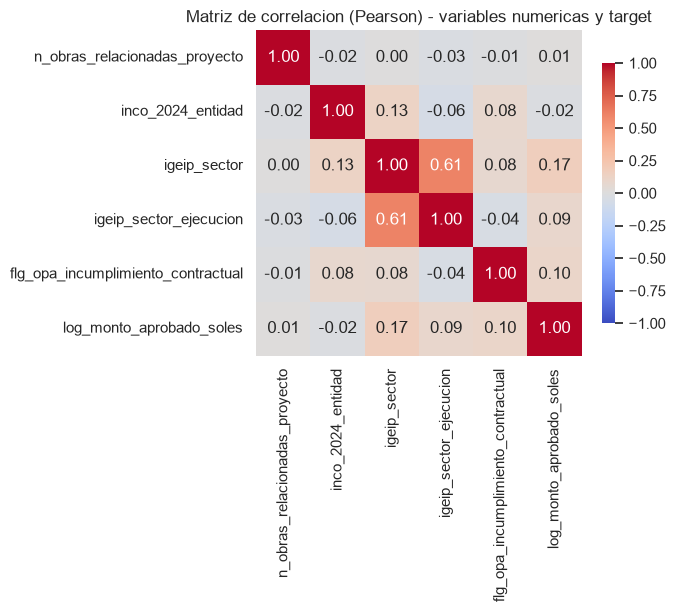

In [8]:
columnas_numericas_corr = [
    "n_obras_relacionadas_proyecto", *columnas_inco_igeip, TARGET,
]
df_corr = df_reducido[columnas_numericas_corr].copy()
df_corr["log_monto_aprobado_soles"] = np.log1p(df_reducido["monto_aprobado_soles"])

matriz_correlacion = df_corr.corr(method="pearson")

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    matriz_correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
    square=True, cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title("Matriz de correlacion (Pearson) - variables numericas y target")
plt.tight_layout()
plt.show()


## 2. Preprocesamiento de datos

Decisiones de limpieza (justificadas en comentarios dentro del codigo, replicando el analisis de outliers de `03_feature_engineering.ipynb` seccion `4. Pre-tratamiento de outliers`):

1. Eliminar registros con `monto_aprobado_soles` nulo (solo afecta a la clase mayoritaria, no distorsiona el desbalance).
2. `monto_aprobado_soles == 0` es un error de registro: se reemplaza por `monto_aprobacion_et` (el monto del expediente tecnico aprobado, una referencia razonable del monto real).
3. `monto_aprobado_soles == 1` es un valor invalido residual: se descarta ese registro.
4. La escala de `monto_aprobado_soles` es fuertemente asimetrica (ver histograma anterior): se trata con winsorizacion (p99) + log1p **dentro del pipeline de modelado** (no aqui), para que el limite de winsorizacion se aprenda solo con datos de entrenamiento.
5. Los nulos de `inco_2024_entidad`, `igeip_sector` e `igeip_sector_ejecucion` se imputan con la **mediana** dentro del pipeline (`build_numeric_pipeline` usa `SimpleImputer(strategy="median")` por defecto), tambien ajustada solo con train.

In [9]:
# 1. Eliminar nulos en monto_aprobado_soles
n_antes = len(df_reducido)
df_reducido = df_reducido.dropna(subset=["monto_aprobado_soles"])
print(f"Eliminados por monto nulo: {n_antes - len(df_reducido):,}")

# 2. monto_aprobado_soles == 0 -> reemplazar por monto_aprobacion_et
mask_monto_cero = df_reducido["monto_aprobado_soles"] == 0
df_reducido.loc[mask_monto_cero, "monto_aprobado_soles"] = df_reducido.loc[
    mask_monto_cero, "monto_aprobacion_et"
]
print(f"Corregidos (monto == 0): {mask_monto_cero.sum():,}")

# 3. monto_aprobado_soles == 1 -> registro invalido, se descarta
n_antes = len(df_reducido)
df_reducido = df_reducido[df_reducido["monto_aprobado_soles"] != 1].copy()
print(f"Eliminados (monto == 1): {n_antes - len(df_reducido):,}")


Eliminados por monto nulo: 18
Corregidos (monto == 0): 22
Eliminados (monto == 1): 1


## 3. Proceso de Feature Engineering

**Variable temporal (lag / media movil).** Aunque cada fila representa un proyecto distinto (no es una serie de tiempo con una sola entidad repetida), varias obras comparten `codigo_entidad` a lo largo de los anios. Se construye una **tasa historica movil (expanding mean) de paralizacion por entidad**, usando en cada fila unicamente las obras *anteriores en el tiempo* de esa misma entidad (`shift(1)` excluye la fila actual): es el analogo, para datos panel, de un lag/media movil en series de tiempo, y es estrictamente causal (no usa informacion futura) por lo que puede calcularse antes de la particion train/test sin fuga de datos. Para la primera obra de una entidad (sin historia previa) se usa la tasa historica global acumulada hasta esa fecha.

**Codificacion de variables categoricas** (dentro del pipeline de modelado, seccion 5, para que se ajuste por fold en la validacion cruzada) e **inclusion de INCO/IGEIP**:

| Columnas | Metodo |
|---|---|
| `tipo_obra_nivel_2`, `tipo_obra_nivel_3`, `departamento`, `provincia` | Target encoding bayesiano (suavizado) |
| `codigo_entidad`, `sector_entidad` | WOE (suavizado) |
| `naturaleza_obra`, `tipo_formato`, `tipo_obra_nivel_1` | One-hot |
| `monto_aprobado_soles` | Winsorizacion (p99) + log1p + estandarizacion |
| `n_obras_relacionadas_proyecto`, `tasa_historica_movil_entidad`, `inco_2024_entidad`, `igeip_sector`, `igeip_sector_ejecucion` | Imputacion por mediana + estandarizacion |

In [10]:
df_reducido[DATE_COL] = pd.to_datetime(df_reducido[DATE_COL], errors="coerce")
df_reducido = df_reducido.dropna(subset=[DATE_COL, TARGET])
df_reducido = df_reducido.sort_values(DATE_COL).reset_index(drop=True)

# Media movil (expanding) causal de la tasa de paralizacion por entidad.
tasa_por_entidad_previa = (
    df_reducido.groupby("codigo_entidad")[TARGET]
    .apply(lambda serie: serie.expanding().mean().shift(1))
    .reset_index(level=0, drop=True)
)
tasa_global_previa = df_reducido[TARGET].expanding().mean().shift(1)

df_reducido["tasa_historica_movil_entidad"] = (
    tasa_por_entidad_previa.fillna(tasa_global_previa).fillna(df_reducido[TARGET].mean())
)

df_reducido[["codigo_entidad", DATE_COL, TARGET, "tasa_historica_movil_entidad"]].head(10)


,codigo_entidad,fecha_inicio_obra,flg_opa_incumplimiento_contractual,tasa_historica_movil_entidad
0,6012.0,2010-12-18,0,0.07499
1,6352.0,2012-08-25,0,0.00000
2,282.0,2012-12-28,0,0.00000
3,282.0,2012-12-28,0,0.00000
4,282.0,2013-02-26,0,0.00000
5,6012.0,2013-03-01,0,0.00000
6,284.0,2013-08-11,0,0.00000
7,312.0,2013-10-17,0,0.00000
8,6012.0,2014-04-08,0,0.00000
9,6012.0,2014-06-17,1,0.00000


In [11]:
# Definicion de los grupos de columnas usados por el preprocesador (seccion 5)
columnas_target_encoding = ["tipo_obra_nivel_2", "tipo_obra_nivel_3", "departamento", "provincia"]
columnas_woe = ["codigo_entidad", "sector_entidad"]
columnas_onehot = ["naturaleza_obra", "tipo_formato", "tipo_obra_nivel_1"]
columnas_monto = ["monto_aprobado_soles"]
columnas_numericas = [
    "n_obras_relacionadas_proyecto", "tasa_historica_movil_entidad",
    *columnas_inco_igeip,
]

columnas_features = (
    columnas_target_encoding + columnas_woe + columnas_onehot
    + columnas_monto + columnas_numericas
)


## 4. Definicion del esquema experimental

**Particion train/test**: temporal (no aleatoria). Se ordena por `fecha_inicio_obra` y se separa el 65% mas antiguo para entrenamiento y el 35% mas reciente para prueba, ya que el fenomeno es intrinsecamente temporal (se usa la historia de ejecuciones pasadas para estimar el riesgo de obras futuras); una particion aleatoria filtraria informacion del futuro hacia el pasado.

El test set queda completamente aislado hasta la evaluacion final (seccion 5). Toda la seleccion de modelo e hiperparametros usa **solo el train**, con `TimeSeriesSplit` (los folds tambien respetan el orden temporal, sin mezclar pasado y futuro dentro de la validacion cruzada).

In [12]:
split_idx = int(len(df_reducido) * 0.62)
df_train = df_reducido.iloc[:split_idx].copy()
df_test = df_reducido.iloc[split_idx:].copy()

X_train = df_train[columnas_features]
y_train = df_train[TARGET]
X_test = df_test[columnas_features]
y_test = df_test[TARGET]

print(f"Train: {len(df_train):,} | {df_train[DATE_COL].min().date()} a {df_train[DATE_COL].max().date()} | tasa positiva: {y_train.mean():.4f}")
print(f"Test : {len(df_test):,} | {df_test[DATE_COL].min().date()} a {df_test[DATE_COL].max().date()} | tasa positiva: {y_test.mean():.4f}")


Train: 1,628 | 2010-12-18 a 2022-10-22 | tasa positiva: 0.0848
Test : 999 | 2022-10-22 a 2025-12-20 | tasa positiva: 0.0591


## 5. Entrenamiento de modelos

Se comparan **8 modelos**:

- **5.1 `M0`** — regresion logistica *sin* penalizar ni ponderar (`statsmodels.Logit`, MLE simple): referencia "ingenua" que expone el problema del desbalance de clases (se espera recall muy bajo al umbral 0.5, motivando el resto de la seccion).
- **5.2 `M2` y `RF`** — regresion logistica penalizada (Elastic Net) y Random Forest, ambos con ponderacion de clase (`class_weight="balanced"` / `"balanced_subsample"`), seleccionados/afinados via **validacion cruzada anidada + busqueda de hiperparametros**. Se evaluan **ambos** en test (no solo el que resulte finalista) para que todo modelo entrenado en el notebook aparezca en la comparativa final.
- **5.3 `M4`, `M5`, `M6`, `M7`, `M8`** — GLM/GAM con distintas funciones de enlace, **ponderados por clase** (ver justificacion de la ponderacion abajo). No pasan por `GridSearchCV` porque `statsmodels` no expone una interfaz de hiperparametros compatible con `scikit-learn`; cada uno es una **especificacion teorica distinta** que se compara por AIC/BIC/log-verosimilitud y por desempenio en test, siguiendo el enfoque de comparacion de modelos GLM de `Laboratorio4_GLM_PCA_2026I_MIES.ipynb`.
- **5.4** — comparativa final con los 8 modelos.

### Por que M4-M8 necesitan una estrategia de desbalance (y por que no es sampling)

Un GLM/GAM ajustado por maxima verosimilitud sin ponderar (como `M0`) produce probabilidades **bien calibradas** a la tasa real de paralizacion (~7-8%): es matematicamente correcto, pero implica que casi ninguna observacion supera el umbral de decision por defecto (0.5), y por lo tanto el recall se desploma (no es que el modelo sea malo prediciendo el riesgo relativo -su AUC puede ser razonable-, sino que el umbral de 0.5 es demasiado alto para una clase tan minoritaria).

**No se usa sobre/sub-muestreo (SMOTE, undersampling, etc.)**: alterar la proporcion de clases en los datos de entrenamiento distorsiona la probabilidad base que un GLM/GAM esta diseniado para estimar via maxima verosimilitud (el intercepto deja de estimar el log-odds/log-riesgo real de la poblacion), lo cual complica la interpretacion de los coeficientes/odds ratios -precisamente lo que se pide poder interpretar-. En su lugar, se usan **pesos de caso (`freq_weights` en `statsmodels.GLM`, `weights=` en `GLMGam.fit()`)**: cada observacion pondera su contribucion a la log-verosimilitud segun el inverso de la frecuencia de su clase (formula identica a `class_weight="balanced"` de scikit-learn). Esto es un **ajuste ponderado por maxima verosimilitud** (una forma de aprendizaje costo-sensible), no un cambio en los datos: preserva el tamanio de muestra observado y sigue siendo una estimacion de maxima verosimilitud valida, solo que penaliza mas el error sobre la clase minoritaria.

### 5.1. Modelo base (M0): regresion logistica sin penalizar ni ponderar

In [13]:
preprocesador_base = build_preprocessor(
    amount_log_columns=columnas_monto,
    numeric_columns=columnas_numericas,
    categorical_columns=columnas_onehot,
    target_encoded_columns=columnas_target_encoding,
    woe_columns=columnas_woe,
)

Xt_train = preprocesador_base.fit_transform(X_train, y_train)
Xt_test = preprocesador_base.transform(X_test)
if hasattr(Xt_train, "toarray"):
    Xt_train = Xt_train.toarray()
    Xt_test = Xt_test.toarray()

nombres_features = list(preprocesador_base.get_feature_names_out())

# Se quita una dummy de referencia por columna one-hot: al agregar una
# constante, un one-hot completo (todas las categorias) genera colinealidad
# perfecta con el intercepto (las dummies de cada variable suman 1).
columnas_glm = columnas_sin_colinealidad(nombres_features, columnas_onehot)
indices_glm = [nombres_features.index(c) for c in columnas_glm]

X_train_logit = Xt_train[:, indices_glm]
X_test_logit = Xt_test[:, indices_glm]

# Pesos de clase balanceados (misma formula que sklearn class_weight="balanced":
# peso_c = n_muestras / (n_clases * n_muestras_c)), usados en M2/RF/M4/M5/M6/M7.
n_train_total = len(y_train)
n_train_pos = (y_train == 1).sum()
n_train_neg = (y_train == 0).sum()
pesos_balanceados_train = np.where(
    y_train == 1,
    n_train_total / (2 * n_train_pos),
    n_train_total / (2 * n_train_neg),
)
print(f"Peso clase 1 (paralizada): {n_train_total / (2 * n_train_pos):.4f}")
print(f"Peso clase 0 (no paralizada): {n_train_total / (2 * n_train_neg):.4f}")


Peso clase 1 (paralizada): 5.8986
Peso clase 0 (no paralizada): 0.5463


In [14]:
# Estimacion del modelo de regresion logistica (M0): MLE simple, sin
# ponderar por clase ni penalizar coeficientes.
# El metodo por defecto (Newton-Raphson) no converge aqui: con ~31
# predictores (varias dummies de baja frecuencia) y solo ~144 casos
# positivos en train, la log-verosimilitud es casi plana en algunas
# direcciones (cuasi-separacion) y Newton-Raphson (que depende de un
# Hessiano bien condicionado) se atasca. BFGS (quasi-Newton con busqueda
# de linea) converge a la misma log-verosimilitud con coeficientes mucho
# mas estables -precisamente el problema que motiva penalizar en M2-.
logit_m0 = sm.Logit(y_train.to_numpy(), sm.add_constant(X_train_logit, has_constant="add")).fit(
    method="bfgs", maxiter=1000, disp=0
)
print(logit_m0.summary())


                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 1628
Model:                          Logit   Df Residuals:                     1596
Method:                           MLE   Df Model:                           31
Date:                Fri, 04 Sep 2026   Pseudo R-squ.:                  0.3926
Time:                        22:58:55   Log-Likelihood:                -287.02
converged:                       True   LL-Null:                       -472.54
Covariance Type:            nonrobust   LLR p-value:                 6.786e-60
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.8757    223.602     -0.026      0.979    -444.128     432.377
x1             0.7144      0.166      4.315      0.000       0.390       1.039
x2            -1.8476   4779.350     -0.000      1.0

In [15]:
params = logit_m0.params

or_table_m0 = pd.DataFrame({
    "variable": ["const"] + columnas_glm,
    "Beta": params,
    "Odds_Ratio": np.exp(params),
    "p_value": logit_m0.pvalues,
}).sort_values("Odds_Ratio", ascending=False).reset_index(drop=True)

display(Markdown("**Tabla de odds ratio - M0 (regresion logistica base)**"))
or_table_m0.round(4)


**Tabla de odds ratio - M0 (regresion logistica base)**

,variable,Beta,Odds_Ratio,p_value
0,categorical__tipo_obra_nivel_1_Energía Y Minas,1.7348,5.6676,0.0499
1,woe__codigo_entidad_woe,1.4284,4.1719,0.0000
2,categorical__tipo_obra_nivel_1_Vivienda Constr...,1.3843,3.9921,0.2798
3,categorical__tipo_obra_nivel_1_Educación/Cultura,1.2302,3.4220,0.3737
4,categorical__tipo_obra_nivel_1_Salud,1.1854,3.2721,0.3831
5,categorical__naturaleza_obra_Rehabilitación,1.1457,3.1445,0.1199
6,categorical__tipo_obra_nivel_1_Otras Infraestr...,1.1254,3.0815,0.3694
7,categorical__naturaleza_obra_Remodelación,1.1204,3.0660,0.1544
8,target_encoded__provincia_target_enc,0.9164,2.5002,0.0000
9,categorical__tipo_obra_nivel_1_Transportes Y C...,0.8082,2.2438,0.3937


**Metricas globales - M0 - Regresion logistica base (test, umbral=0.5)**

|             |   valor |
|:------------|--------:|
| roc_auc     |  0.6888 |
| pr_auc      |  0.1797 |
| gini        |  0.3777 |
| brier_score |  0.0614 |
| precision   |  0.1923 |
| recall      |  0.0847 |
| f1          |  0.1176 |
| f2          |  0.0954 |

**Reporte de clasificacion - M0 - Regresion logistica base (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.945 |    0.978 |      0.961 |   940     |
| 1            |       0.192 |    0.085 |      0.118 |    59     |
| accuracy     |       0.925 |    0.925 |      0.925 |     0.925 |
| macro avg    |       0.568 |    0.531 |      0.539 |   999     |
| weighted avg |       0.9   |    0.925 |      0.911 |   999     |

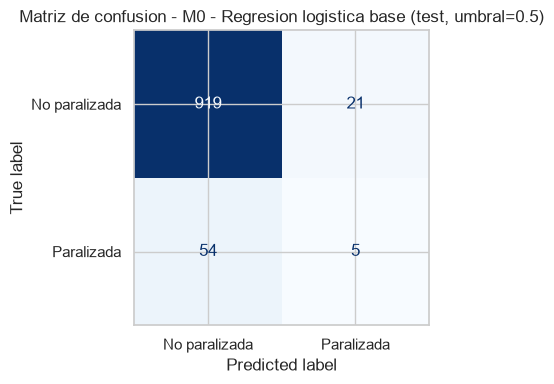

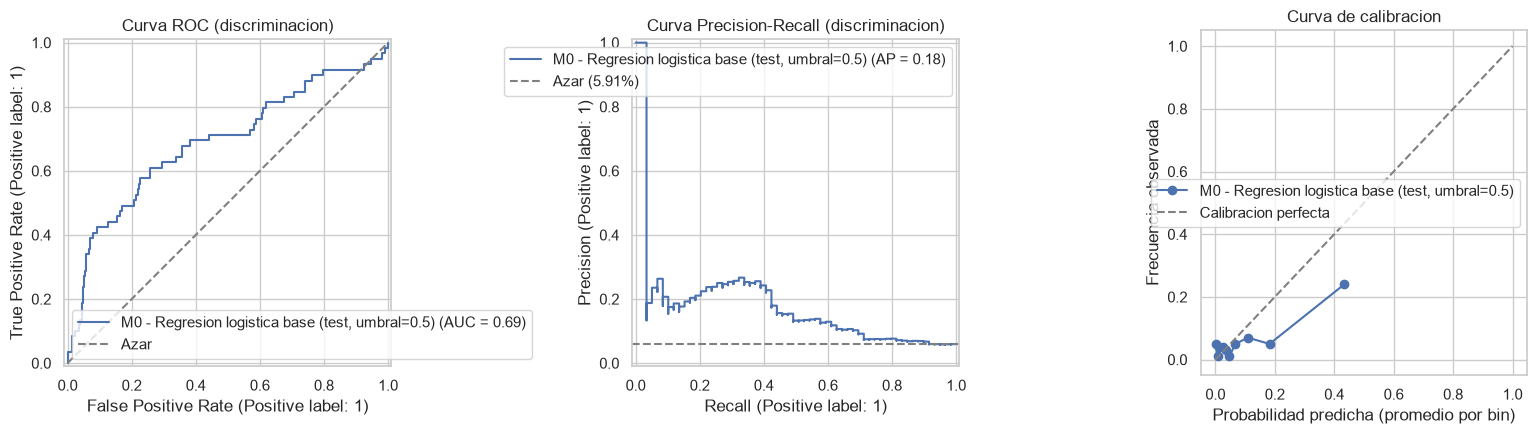

In [16]:
X_test_logit_const = sm.add_constant(X_test_logit, has_constant="add")
y_proba_m0 = np.asarray(logit_m0.predict(X_test_logit_const))
y_pred_m0 = (y_proba_m0 >= 0.5).astype(int)

metrics_m0 = reporte_evaluacion(
    y_test, y_pred_m0, y_proba_m0,
    nombre_modelo="M0 - Regresion logistica base (test, umbral=0.5)"
)


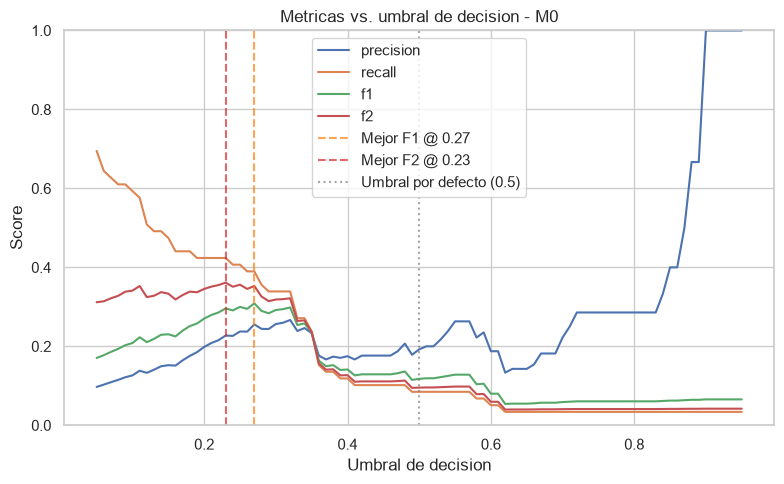

**Mejor umbral por F2 (prioriza recall) - M0**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.23 |      0.2273 |   0.4237 | 0.2959 | 0.3613 |

In [17]:
umbrales_m0 = analizar_umbrales(y_test, y_proba_m0)
mejor_f1_m0, mejor_f2_m0 = graficar_umbrales(umbrales_m0, nombre_modelo="M0")
UMBRAL_DECISION_M0 = mejor_f2_m0["umbral"]

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M0**"))
display(Markdown(mejor_f2_m0.to_frame().T.round(4).to_markdown(index=False)))


### 5.2. M2 y RF: seleccion via validacion cruzada anidada y ajuste de hiperparametros

Dos familias compatibles con `scikit-learn` (por lo tanto con busqueda automatica de hiperparametros), ambas envueltas en un `Pipeline` (preprocesador + clasificador) para que target encoding/WOE se ajusten de forma independiente en cada fold: **M2** (regresion logistica Elastic Net, `class_weight="balanced"`) y **RF** (Random Forest, `class_weight="balanced_subsample"`). `GridSearchCV` (bucle interno, `TimeSeriesSplit` de 3 folds) se evalua con `cross_validate` (bucle externo, `TimeSeriesSplit` de 5 folds) para comparar ambas familias sin que el bucle externo vea los datos usados para elegir hiperparametros en ese mismo fold. Luego **ambas** familias se afinan sobre todo el train y se evaluan en test (no solo la finalista), para que M2 y RF aparezcan en la comparativa de 5.4.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, fbeta_score

preprocesador = build_preprocessor(
    amount_log_columns=columnas_monto,
    numeric_columns=columnas_numericas,
    categorical_columns=columnas_onehot,
    target_encoded_columns=columnas_target_encoding,
    woe_columns=columnas_woe,
)

pipeline_logit = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("clasificador", LogisticRegression(
        solver="saga", penalty="elasticnet", class_weight="balanced",
        max_iter=3000, random_state=RANDOM_STATE,
    )),
])
grid_logit = {
    "clasificador__C": [0.01, 0.1, 1.0, 10.0],
    "clasificador__l1_ratio": [0.0, 0.5, 1.0],
}

pipeline_rf = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("clasificador", RandomForestClassifier(
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1,
    )),
])
grid_rf = {
    "clasificador__n_estimators": [200, 500],
    "clasificador__max_depth": [None, 6, 10],
    "clasificador__min_samples_leaf": [1, 5],
}

candidatos = {
    "M2 - Regresion logistica (Elastic Net)": (pipeline_logit, grid_logit),
    "RF - Random Forest": (pipeline_rf, grid_rf),
}


In [19]:
cv_interno = TimeSeriesSplit(n_splits=3)
cv_externo = TimeSeriesSplit(n_splits=5)

scoring_externo = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
}

resultados_nested_cv = {}

for nombre, (pipeline, grid) in candidatos.items():
    busqueda_interna = GridSearchCV(
        pipeline, param_grid=grid, cv=cv_interno,
        scoring="average_precision", n_jobs=-1, refit=True,
    )
    resultado = cross_validate(
        busqueda_interna, X_train, y_train,
        cv=cv_externo, scoring=scoring_externo, n_jobs=1,
        return_estimator=False,
    )
    resultados_nested_cv[nombre] = resultado
    print(f"{nombre}: PR-AUC = {resultado['test_pr_auc'].mean():.4f} +/- {resultado['test_pr_auc'].std():.4f}")


c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\ws\formacion\uni-mi

M2 - Regresion logistica (Elastic Net): PR-AUC = 0.2360 +/- 0.0972
RF - Random Forest: PR-AUC = 0.2691 +/- 0.1449


In [20]:
resumen_nested_cv = pd.DataFrame({
    nombre: {
        "roc_auc_media": resultado["test_roc_auc"].mean(),
        "roc_auc_std": resultado["test_roc_auc"].std(),
        "pr_auc_media": resultado["test_pr_auc"].mean(),
        "pr_auc_std": resultado["test_pr_auc"].std(),
        "f2_media": resultado["test_f2"].mean(),
        "f2_std": resultado["test_f2"].std(),
    }
    for nombre, resultado in resultados_nested_cv.items()
}).T

nombre_finalista = resumen_nested_cv["pr_auc_media"].idxmax()

display(Markdown("**Comparacion de familias de modelos (validacion cruzada anidada, sobre train)**"))
display(resumen_nested_cv.round(4))
print(f"Recomendado por validacion cruzada anidada (mejor PR-AUC): {nombre_finalista}")


**Comparacion de familias de modelos (validacion cruzada anidada, sobre train)**

,roc_auc_media,roc_auc_std,pr_auc_media,pr_auc_std,f2_media,f2_std
M2 - Regresion logistica (Elastic Net),0.6831,0.1063,0.2360,0.0972,0.3258,0.1330
RF - Random Forest,0.7160,0.1003,0.2691,0.1449,0.1771,0.1401


Recomendado por validacion cruzada anidada (mejor PR-AUC): RF - Random Forest


In [21]:
# Se afina y evalua CADA candidato (no solo el finalista) para que M2 y RF
# aparezcan ambos en la comparativa final de 5.4.
modelos_ajustados = {}
metrics_por_candidato = {}

for nombre, (pipeline, grid) in candidatos.items():
    busqueda = GridSearchCV(
        pipeline, param_grid=grid, cv=TimeSeriesSplit(n_splits=3),
        scoring="average_precision", n_jobs=-1, refit=True,
    )
    busqueda.fit(X_train, y_train)
    print(f"{nombre}: mejores hiperparametros = {busqueda.best_params_} (PR-AUC CV = {busqueda.best_score_:.4f})")
    modelos_ajustados[nombre] = busqueda.best_estimator_


c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


M2 - Regresion logistica (Elastic Net): mejores hiperparametros = {'clasificador__C': 0.01, 'clasificador__l1_ratio': 0.0} (PR-AUC CV = 0.2050)
RF - Random Forest: mejores hiperparametros = {'clasificador__max_depth': 6, 'clasificador__min_samples_leaf': 5, 'clasificador__n_estimators': 200} (PR-AUC CV = 0.2457)


**Metricas globales - M2 - Regresion logistica (Elastic Net) (test, umbral=0.5)**

|             |   valor |
|:------------|--------:|
| roc_auc     |  0.6609 |
| pr_auc      |  0.1504 |
| gini        |  0.3218 |
| brier_score |  0.2049 |
| precision   |  0.1065 |
| recall      |  0.5593 |
| f1          |  0.1789 |
| f2          |  0.3022 |

**Reporte de clasificacion - M2 - Regresion logistica (Elastic Net) (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.962 |    0.705 |      0.814 |   940     |
| 1            |       0.106 |    0.559 |      0.179 |    59     |
| accuracy     |       0.697 |    0.697 |      0.697 |     0.697 |
| macro avg    |       0.534 |    0.632 |      0.496 |   999     |
| weighted avg |       0.912 |    0.697 |      0.776 |   999     |

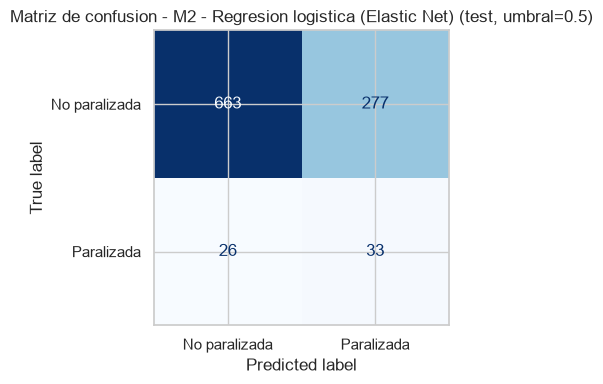

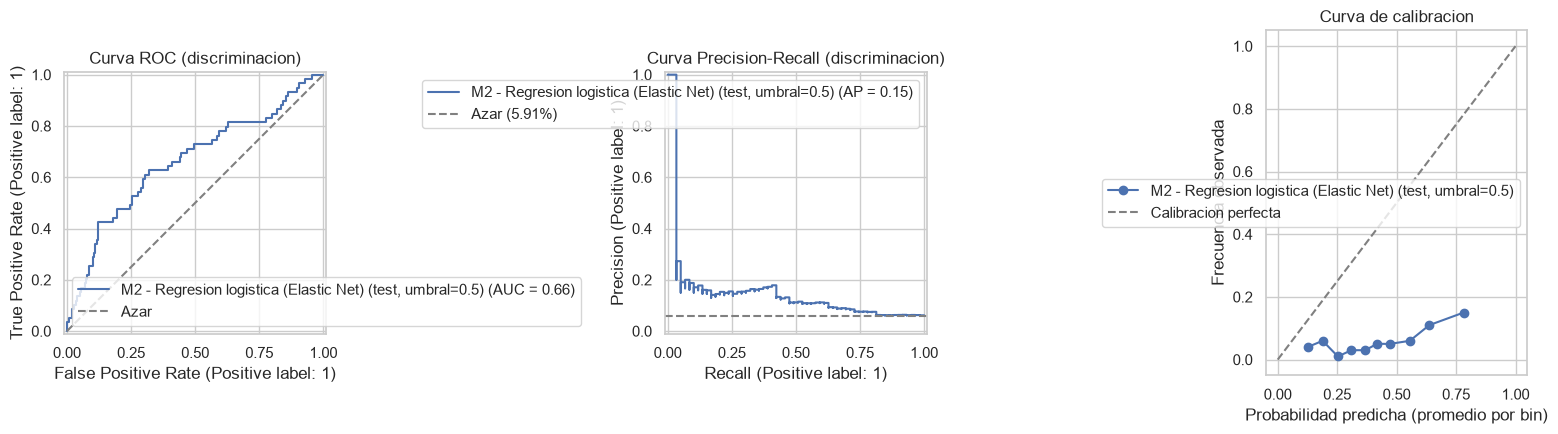

**Metricas globales - RF - Random Forest (test, umbral=0.5)**

|             |   valor |
|:------------|--------:|
| roc_auc     |  0.6334 |
| pr_auc      |  0.139  |
| gini        |  0.2668 |
| brier_score |  0.1345 |
| precision   |  0.1405 |
| recall      |  0.4407 |
| f1          |  0.2131 |
| f2          |  0.3088 |

**Reporte de clasificacion - RF - Random Forest (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.959 |    0.831 |      0.891 |   940     |
| 1            |       0.141 |    0.441 |      0.213 |    59     |
| accuracy     |       0.808 |    0.808 |      0.808 |     0.808 |
| macro avg    |       0.55  |    0.636 |      0.552 |   999     |
| weighted avg |       0.911 |    0.808 |      0.851 |   999     |

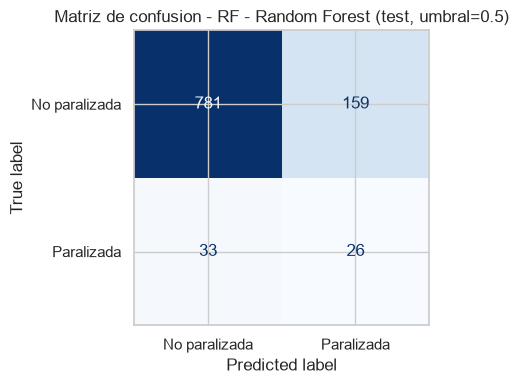

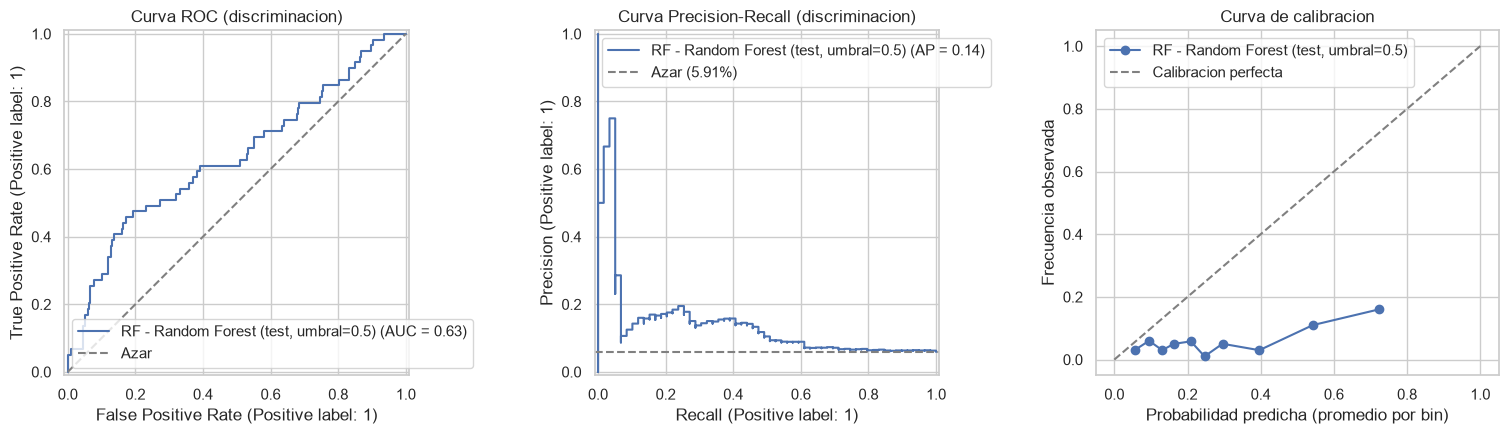

In [22]:
for nombre, modelo in modelos_ajustados.items():
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    metrics_por_candidato[nombre] = reporte_evaluacion(
        y_test, y_pred, y_proba, nombre_modelo=f"{nombre} (test, umbral=0.5)"
    )

metrics_m2 = metrics_por_candidato["M2 - Regresion logistica (Elastic Net)"]
metrics_rf = metrics_por_candidato["RF - Random Forest"]


In [23]:
for nombre, modelo in modelos_ajustados.items():
    nombres_features_modelo = modelo.named_steps["preprocesador"].get_feature_names_out()
    clasificador = modelo.named_steps["clasificador"]
    if isinstance(clasificador, LogisticRegression):
        importancia_lineal_sklearn(clasificador, nombres_features_modelo, nombre_modelo=nombre)
    else:
        importancia_arbol(clasificador, nombres_features_modelo, nombre_modelo=nombre)


**Variables, coeficientes y odds ratios - M2 - Regresion logistica (Elastic Net)**

`odds_ratio = exp(coeficiente)`: cuanto se multiplican los momios (odds) de paralizacion por cada unidad de la variable, manteniendo lo demas constante.

| variable                                                           |   coeficiente |   odds_ratio |   abs_coeficiente |
|:-------------------------------------------------------------------|--------------:|-------------:|------------------:|
| target_encoded__provincia_target_enc                               |        0.5743 |       1.7759 |            0.5743 |
| amount_log__monto_aprobado_soles_winsor_log                        |        0.5553 |       1.7425 |            0.5553 |
| woe__codigo_entidad_woe                                            |        0.4077 |       1.5034 |            0.4077 |
| categorical__naturaleza_obra_Instalación                           |       -0.286  |       0.7513 |            0.286  |
| categorical__naturaleza_obra_Rehabilitación                        |        0.2378 |       1.2684 |            0.2378 |
| numeric_standard__tasa_historica_movil_entidad                     |        0.2003 |       1.2218 |            0.2003 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |        0.1936 |       1.2136 |            0.1936 |
| categorical__tipo_formato_5.0                                      |        0.1607 |       1.1743 |            0.1607 |
| woe__sector_entidad_woe                                            |        0.1162 |       1.1232 |            0.1162 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |       -0.1087 |       0.897  |            0.1087 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |        0.1069 |       1.1128 |            0.1069 |
| categorical__naturaleza_obra_Construcción/Creación                 |       -0.1059 |       0.8995 |            0.1059 |
| categorical__naturaleza_obra_Renovación                            |        0.1037 |       1.1093 |            0.1037 |
| categorical__tipo_formato_1.0                                      |       -0.0849 |       0.9186 |            0.0849 |
| numeric_standard__inco_2024_entidad                                |        0.0802 |       1.0835 |            0.0802 |
| categorical__tipo_formato_2.0                                      |       -0.0774 |       0.9255 |            0.0774 |
| categorical__tipo_obra_nivel_1_Salud                               |        0.0729 |       1.0756 |            0.0729 |
| categorical__naturaleza_obra_Reconstrucción                        |        0.0679 |       1.0703 |            0.0679 |
| numeric_standard__n_obras_relacionadas_proyecto                    |       -0.0631 |       0.9388 |            0.0631 |
| categorical__naturaleza_obra_Remodelación                          |        0.0566 |       1.0583 |            0.0566 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |       -0.0517 |       0.9497 |            0.0517 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |        0.0379 |       1.0386 |            0.0379 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |       -0.0351 |       0.9655 |            0.0351 |
| numeric_standard__igeip_sector                                     |       -0.035  |       0.9656 |            0.035  |
| categorical__tipo_obra_nivel_1_Agricultura                         |       -0.0341 |       0.9665 |            0.0341 |
| categorical__naturaleza_obra_Mejoramiento                          |       -0.0316 |       0.9688 |            0.0316 |
| categorical__naturaleza_obra_Ampliación                            |       -0.0234 |       0.9769 |            0.0234 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |        0.0172 |       1.0174 |            0.0172 |
| numeric_standard__igeip_sector_ejecucion                           |        0.0165 |       1.0166 |            0.0165 |
| categorical__naturaleza_obra_Reparación                            |       -0.0163 |       0.9839 |            0.0163 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |        0.0138 |       1.0139 |            0.0138 |
| target_encoded__departamento_target_enc                            |       -0.0116 |       0.9884 |            0.0116 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |       -0.007  |       0.993  |            0.007  |
| categorical__naturaleza_obra_infrequent_sklearn                    |       -0.0044 |       0.9956 |            0.0044 |

**Variables e importancia (impureza) - RF - Random Forest**

| variable                                                           |   importancia |
|:-------------------------------------------------------------------|--------------:|
| woe__codigo_entidad_woe                                            |        0.1807 |
| amount_log__monto_aprobado_soles_winsor_log                        |        0.1589 |
| target_encoded__provincia_target_enc                               |        0.1437 |
| numeric_standard__tasa_historica_movil_entidad                     |        0.1012 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |        0.0759 |
| woe__sector_entidad_woe                                            |        0.0554 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |        0.0409 |
| categorical__naturaleza_obra_Instalación                           |        0.0328 |
| numeric_standard__inco_2024_entidad                                |        0.0322 |
| target_encoded__departamento_target_enc                            |        0.0314 |
| categorical__naturaleza_obra_Rehabilitación                        |        0.0213 |
| numeric_standard__igeip_sector_ejecucion                           |        0.0196 |
| categorical__tipo_formato_2.0                                      |        0.019  |
| numeric_standard__igeip_sector                                     |        0.0189 |
| categorical__tipo_formato_5.0                                      |        0.0124 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |        0.0085 |
| categorical__tipo_formato_1.0                                      |        0.0065 |
| categorical__naturaleza_obra_Construcción/Creación                 |        0.0054 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |        0.0053 |
| categorical__naturaleza_obra_Mejoramiento                          |        0.0038 |
| categorical__naturaleza_obra_Reconstrucción                        |        0.0038 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |        0.0035 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |        0.0033 |
| categorical__tipo_obra_nivel_1_Agricultura                         |        0.0029 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |        0.0025 |
| categorical__naturaleza_obra_Remodelación                          |        0.0025 |
| categorical__tipo_obra_nivel_1_Salud                               |        0.0022 |
| categorical__naturaleza_obra_Ampliación                            |        0.0019 |
| categorical__naturaleza_obra_Renovación                            |        0.0019 |
| categorical__naturaleza_obra_Reparación                            |        0.0008 |
| categorical__naturaleza_obra_infrequent_sklearn                    |        0.0007 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |        0.0002 |
| numeric_standard__n_obras_relacionadas_proyecto                    |        0      |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |        0      |

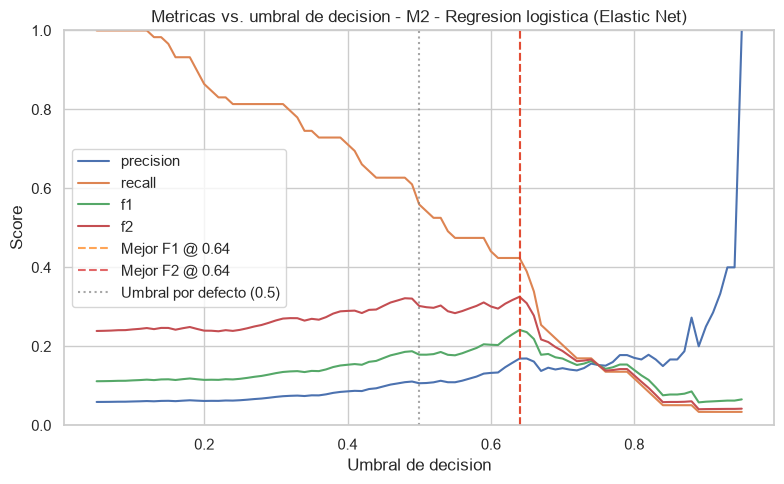

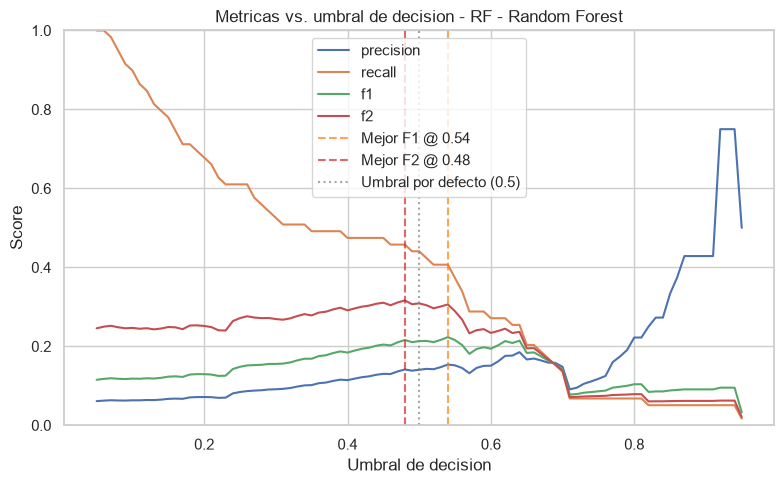

In [24]:
for nombre, modelo in modelos_ajustados.items():
    y_proba = modelo.predict_proba(X_test)[:, 1]
    umbrales = analizar_umbrales(y_test, y_proba)
    graficar_umbrales(umbrales, nombre_modelo=nombre)


### 5.3. Modelos GLM / GAM ponderados por clase (M4, M5, M6, M7, M8)

#### M4: GLM binomial con enlace c-loglog (ponderado)

AIC: 1302.08 | BIC: 1474.73 | Log-verosimilitud: -619.04


**Metricas globales - M4 - GLM c-loglog ponderado (test, umbral=0.5)**

|             |   valor |
|:------------|--------:|
| roc_auc     |  0.6861 |
| pr_auc      |  0.1686 |
| gini        |  0.3723 |
| brier_score |  0.1873 |
| precision   |  0.1314 |
| recall      |  0.6102 |
| f1          |  0.2162 |
| f2          |  0.3529 |

**Reporte de clasificacion - M4 - GLM c-loglog ponderado (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.968 |    0.747 |      0.843 |   940     |
| 1            |       0.131 |    0.61  |      0.216 |    59     |
| accuracy     |       0.739 |    0.739 |      0.739 |     0.739 |
| macro avg    |       0.55  |    0.678 |      0.53  |   999     |
| weighted avg |       0.919 |    0.739 |      0.806 |   999     |

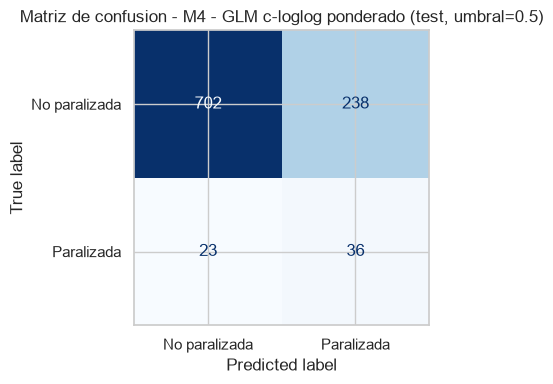

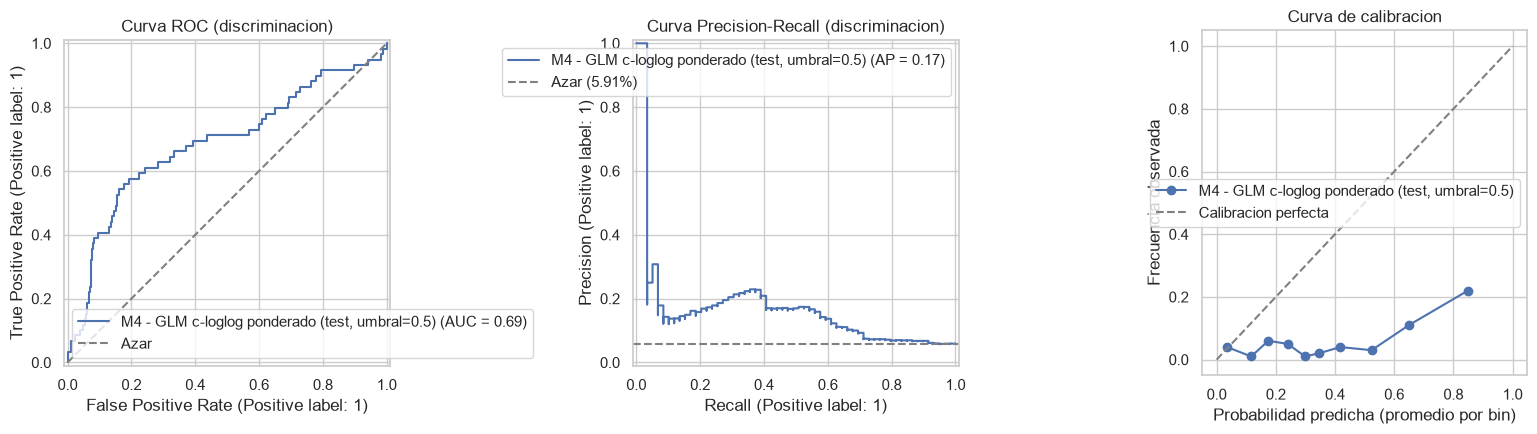

**Variables, coeficientes y p-valores - M4 - GLM c-loglog ponderado**

`razon_riesgo = exp(coeficiente)`: bajo el enlace c-loglog (modelo de riesgos proporcionales en tiempo discreto), es la razon de riesgos (hazard ratio) de paralizacion por cada unidad de la variable.

| variable                                                           |   coeficiente |   p_valor |   razon_riesgo |   abs_coeficiente |
|:-------------------------------------------------------------------|--------------:|----------:|---------------:|------------------:|
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |      -26.8121 |    0.9999 |         0      |           26.8121 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |       -7.8793 |    0.9185 |         0.0004 |            7.8793 |
| numeric_standard__n_obras_relacionadas_proyecto                    |       -6.3232 |    1      |         0.0018 |            6.3232 |
| const                                                              |       -2.81   |    1      |         0.0602 |            2.81   |
| categorical__naturaleza_obra_Instalación                           |       -1.9444 |    0.0001 |         0.1431 |            1.9444 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |        0.9136 |    0.0039 |         2.4932 |            0.9136 |
| woe__codigo_entidad_woe                                            |        0.8838 |    0      |         2.4201 |            0.8838 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |        0.8065 |    0.0857 |         2.24   |            0.8065 |
| categorical__naturaleza_obra_Remodelación                          |        0.7915 |    0.0115 |         2.2066 |            0.7915 |
| categorical__naturaleza_obra_Rehabilitación                        |        0.7428 |    0.0117 |         2.1017 |            0.7428 |
| categorical__tipo_obra_nivel_1_Salud                               |        0.7399 |    0.137  |         2.0958 |            0.7399 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |        0.6797 |    0.1105 |         1.9733 |            0.6797 |
| categorical__naturaleza_obra_Renovación                            |        0.6056 |    0.0415 |         1.8323 |            0.6056 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |        0.5554 |    0.2669 |         1.7427 |            0.5554 |
| categorical__naturaleza_obra_Reconstrucción                        |        0.5502 |    0.0818 |         1.7335 |            0.5502 |
| target_encoded__provincia_target_enc                               |        0.5375 |    0      |         1.7117 |            0.5375 |
| amount_log__monto_aprobado_soles_winsor_log                        |        0.4814 |    0      |         1.6183 |            0.4814 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |        0.3753 |    0.2794 |         1.4555 |            0.3753 |
| numeric_standard__inco_2024_entidad                                |        0.2487 |    0.0012 |         1.2824 |            0.2487 |
| categorical__tipo_formato_5.0                                      |        0.239  |    0.3239 |         1.27   |            0.239  |
| categorical__naturaleza_obra_infrequent_sklearn                    |        0.2262 |    0.6067 |         1.2538 |            0.2262 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |        0.1977 |    0.0016 |         1.2185 |            0.1977 |
| categorical__tipo_formato_2.0                                      |        0.165  |    0.3461 |         1.1794 |            0.165  |
| numeric_standard__igeip_sector_ejecucion                           |        0.1283 |    0.3856 |         1.1368 |            0.1283 |
| target_encoded__departamento_target_enc                            |       -0.1147 |    0.025  |         0.8916 |            0.1147 |
| categorical__naturaleza_obra_Mejoramiento                          |        0.0842 |    0.7039 |         1.0878 |            0.0842 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |       -0.0776 |    0.5185 |         0.9254 |            0.0776 |
| woe__sector_entidad_woe                                            |        0.0602 |    0.7417 |         1.062  |            0.0602 |
| numeric_standard__igeip_sector                                     |       -0.0446 |    0.79   |         0.9564 |            0.0446 |
| categorical__naturaleza_obra_Construcción/Creación                 |       -0.0399 |    0.8751 |         0.9609 |            0.0399 |
| numeric_standard__tasa_historica_movil_entidad                     |        0.0384 |    0.2664 |         1.0391 |            0.0384 |
| categorical__naturaleza_obra_Reparación                            |       -0.0013 |    0.9975 |         0.9987 |            0.0013 |

In [25]:
X_design_train_m4 = sm.add_constant(X_train_logit, has_constant="add")
X_design_test_m4 = sm.add_constant(X_test_logit, has_constant="add")

glm_m4 = sm.GLM(
    y_train.to_numpy(),
    X_design_train_m4,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
    freq_weights=pesos_balanceados_train,
)
result_m4 = glm_m4.fit(method="bfgs", maxiter=1000)

aic_m4, bic_m4 = calcular_aic_bic(result_m4.llf, len(result_m4.params), len(y_train))
print(f"AIC: {aic_m4:.2f} | BIC: {bic_m4:.2f} | Log-verosimilitud: {result_m4.llf:.2f}")

y_proba_m4 = np.asarray(result_m4.predict(X_design_test_m4))
y_pred_m4 = (y_proba_m4 >= 0.5).astype(int)

metrics_m4 = reporte_evaluacion(
    y_test, y_pred_m4, y_proba_m4,
    nombre_modelo="M4 - GLM c-loglog ponderado (test, umbral=0.5)"
)
importancia_m4 = importancia_glm_statsmodels(
    result_m4, columnas_glm, nombre_modelo="M4 - GLM c-loglog ponderado", enlace="cloglog"
)


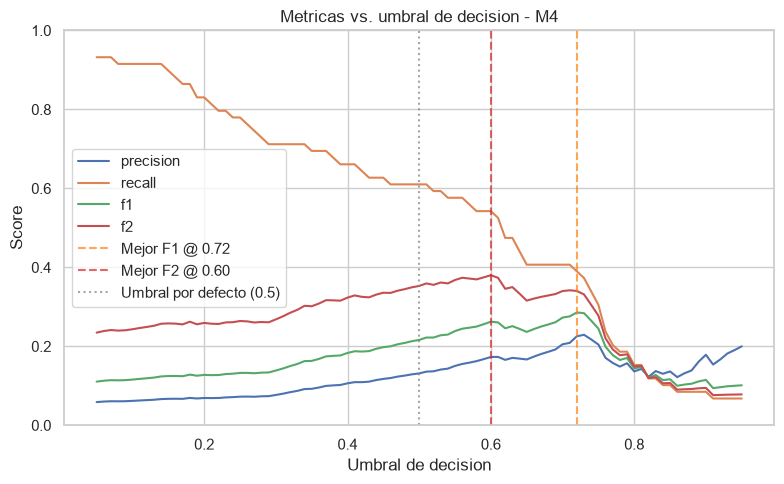

In [26]:
umbrales_m4 = analizar_umbrales(y_test, y_proba_m4)
mejor_f1_m4, mejor_f2_m4 = graficar_umbrales(umbrales_m4, nombre_modelo="M4")
UMBRAL_DECISION_M4 = mejor_f2_m4["umbral"]


#### M5: GLM binomial con enlace probit (ponderado)

AIC: 1308.89 | BIC: 1481.53 | Log-verosimilitud: -622.44


**Metricas globales - M5 - GLM probit ponderado (test, umbral=0.5)**

|             |   valor |
|:------------|--------:|
| roc_auc     |  0.6691 |
| pr_auc      |  0.1541 |
| gini        |  0.3382 |
| brier_score |  0.2028 |
| precision   |  0.1237 |
| recall      |  0.6271 |
| f1          |  0.2067 |
| f2          |  0.3458 |

**Reporte de clasificacion - M5 - GLM probit ponderado (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.969 |    0.721 |      0.827 |   940     |
| 1            |       0.124 |    0.627 |      0.207 |    59     |
| accuracy     |       0.716 |    0.716 |      0.716 |     0.716 |
| macro avg    |       0.546 |    0.674 |      0.517 |   999     |
| weighted avg |       0.919 |    0.716 |      0.79  |   999     |

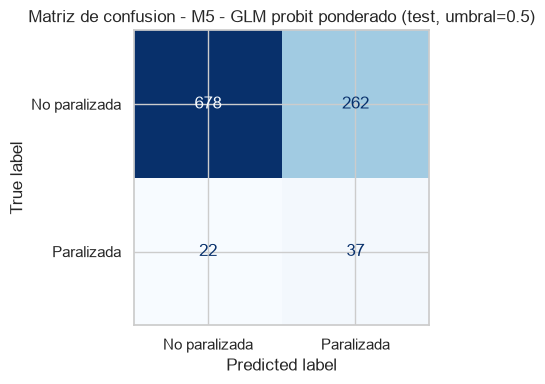

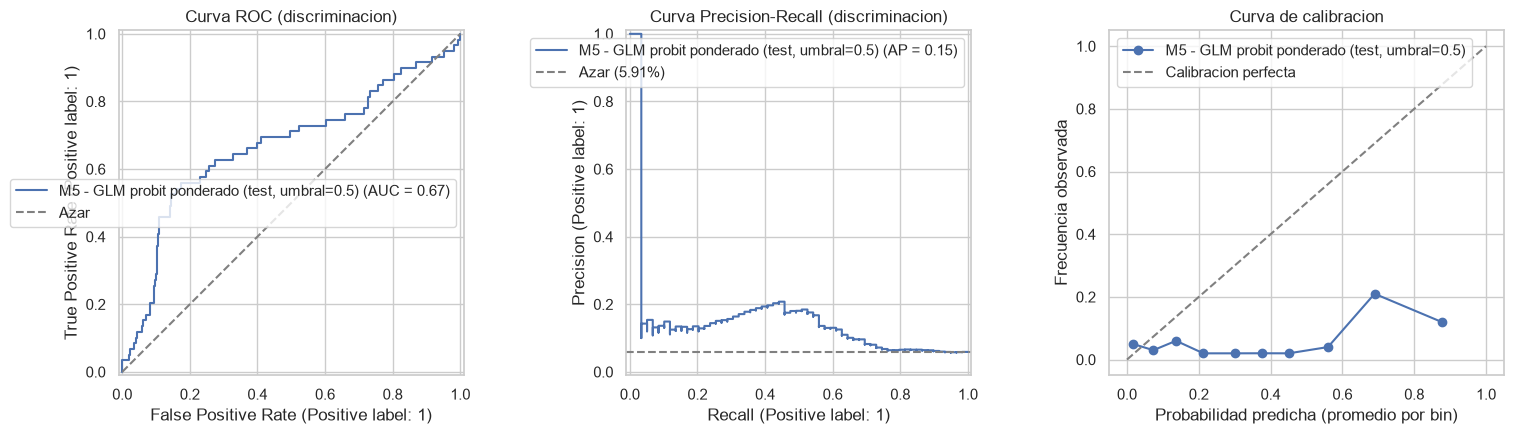

**Variables, coeficientes y p-valores - M5 - GLM probit ponderado**

el enlace probit no tiene una interpretacion multiplicativa cerrada tipo odds/hazard ratio; `exp_coeficiente` se reporta solo como referencia. Para probit se suele interpretar el signo/magnitud relativa del coeficiente, o efectos marginales sobre la probabilidad.

| variable                                                           |   coeficiente |   p_valor |   exp_coeficiente |   abs_coeficiente |
|:-------------------------------------------------------------------|--------------:|----------:|------------------:|------------------:|
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |      -32.6791 |    1      |            0      |           32.6791 |
| numeric_standard__n_obras_relacionadas_proyecto                    |      -15.7974 |    1      |            0      |           15.7974 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |       -5.4297 |    0.9998 |            0.0044 |            5.4297 |
| const                                                              |       -2.7216 |    0.9998 |            0.0658 |            2.7216 |
| categorical__tipo_obra_nivel_1_Salud                               |        1.5015 |    0.0015 |            4.4885 |            1.5015 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |        1.2869 |    0.003  |            3.6215 |            1.2869 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |        1.1395 |    0.0058 |            3.1251 |            1.1395 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |        1.0171 |    0.0006 |            2.7651 |            1.0171 |
| categorical__naturaleza_obra_Instalación                           |       -0.9592 |    0.002  |            0.3832 |            0.9592 |
| categorical__naturaleza_obra_Rehabilitación                        |        0.8477 |    0.001  |            2.3342 |            0.8477 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |        0.8038 |    0.0886 |            2.234  |            0.8038 |
| categorical__naturaleza_obra_Remodelación                          |        0.6809 |    0.0122 |            1.9756 |            0.6809 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |        0.6633 |    0.0385 |            1.9413 |            0.6633 |
| categorical__naturaleza_obra_Renovación                            |        0.5677 |    0.0324 |            1.7643 |            0.5677 |
| woe__codigo_entidad_woe                                            |        0.5355 |    0      |            1.7084 |            0.5355 |
| target_encoded__provincia_target_enc                               |        0.4884 |    0      |            1.6297 |            0.4884 |
| amount_log__monto_aprobado_soles_winsor_log                        |        0.4302 |    0      |            1.5375 |            0.4302 |
| categorical__naturaleza_obra_Reconstrucción                        |        0.4168 |    0.1402 |            1.5171 |            0.4168 |
| numeric_standard__igeip_sector                                     |       -0.3276 |    0.0316 |            0.7207 |            0.3276 |
| categorical__naturaleza_obra_Reparación                            |       -0.2956 |    0.4409 |            0.7441 |            0.2956 |
| numeric_standard__igeip_sector_ejecucion                           |        0.2773 |    0.0369 |            1.3196 |            0.2773 |
| woe__sector_entidad_woe                                            |        0.2179 |    0.1942 |            1.2434 |            0.2179 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |        0.1748 |    0.004  |            1.191  |            0.1748 |
| numeric_standard__inco_2024_entidad                                |        0.1659 |    0.0123 |            1.1804 |            0.1659 |
| categorical__tipo_formato_5.0                                      |        0.1448 |    0.5005 |            1.1558 |            0.1448 |
| categorical__naturaleza_obra_Mejoramiento                          |        0.1122 |    0.5714 |            1.1187 |            0.1122 |
| target_encoded__departamento_target_enc                            |       -0.1027 |    0.0369 |            0.9024 |            0.1027 |
| numeric_standard__tasa_historica_movil_entidad                     |        0.0949 |    0.0101 |            1.0995 |            0.0949 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |        0.0377 |    0.7424 |            1.0385 |            0.0377 |
| categorical__naturaleza_obra_infrequent_sklearn                    |        0.0316 |    0.9332 |            1.0321 |            0.0316 |
| categorical__tipo_formato_2.0                                      |       -0.0165 |    0.9117 |            0.9836 |            0.0165 |
| categorical__naturaleza_obra_Construcción/Creación                 |       -0.0099 |    0.9637 |            0.9902 |            0.0099 |

In [27]:
glm_m5 = sm.GLM(
    y_train.to_numpy(),
    X_design_train_m4,
    family=sm.families.Binomial(link=sm.families.links.Probit()),
    freq_weights=pesos_balanceados_train,
)
result_m5 = glm_m5.fit(method="bfgs", maxiter=1000)

aic_m5, bic_m5 = calcular_aic_bic(result_m5.llf, len(result_m5.params), len(y_train))
print(f"AIC: {aic_m5:.2f} | BIC: {bic_m5:.2f} | Log-verosimilitud: {result_m5.llf:.2f}")

y_proba_m5 = np.asarray(result_m5.predict(X_design_test_m4))
y_pred_m5 = (y_proba_m5 >= 0.5).astype(int)

metrics_m5 = reporte_evaluacion(
    y_test, y_pred_m5, y_proba_m5,
    nombre_modelo="M5 - GLM probit ponderado (test, umbral=0.5)"
)
importancia_m5 = importancia_glm_statsmodels(
    result_m5, columnas_glm, nombre_modelo="M5 - GLM probit ponderado", enlace="probit"
)


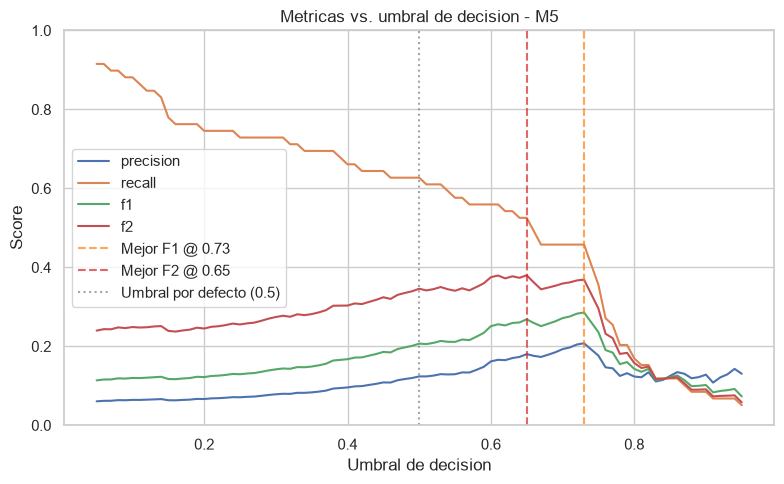

In [28]:
umbrales_m5 = analizar_umbrales(y_test, y_proba_m5)
mejor_f1_m5, mejor_f2_m5 = graficar_umbrales(umbrales_m5, nombre_modelo="M5")
UMBRAL_DECISION_M5 = mejor_f2_m5["umbral"]


#### M6, M7 y M8: GAM ponderado (logit / c-loglog / probit)

Las columnas continuas (`amount_log`, `numeric_standard`, `target_encoded`, `woe`) entran como terminos suaves (splines); las columnas one-hot (`categorical`, ya sin la dummy de referencia) entran como parte lineal. Los tres modelos comparten preprocesamiento y base de splines; solo cambia el enlace del GLM.

**Sobre la extrapolacion de los splines**: `bs_gam` (la base B-spline) se ajusta unicamente con `X_smooth_train`. Si alguna variable en test cae fuera del rango observado en train, `statsmodels` no sabe evaluar la base fuera de esos knots (lanza `NotImplementedError`). Por eso, antes de construir `bs_gam`, `X_smooth_test` se recorta (`np.clip`) a los limites de train — la celda siguiente reporta cuantos valores de test fueron recortados, para verificar que esto se este aplicando y cuantificar su alcance.

> **Nota de estabilidad numerica**: al ponderar por clase (`freq_weights=`/`weights=pesos_balanceados_train`), el ajuste iterativo por defecto de `statsmodels` (IRLS para `GLM`, PIRLS para `GLMGam`) puede divergir para el enlace c-loglog: se observaron casos donde los coeficientes explotan a magnitudes de `~1e14`-`~1e15` y la log-verosimilitud colapsa (de valores razonables ~-600/-650 a ~-7,500/-27,000), arrastrando el AUC en test a ~0.52 (practicamente azar). Esto no fue exclusivo de un enlace o de GAM: tambien ocurrio en `M4` (GLM c-loglog, sin componente aditivo) bajo cierta particion de los datos. Se probaron varias mitigaciones (aumentar la penalizacion de suavizado, usar los parametros de un ajuste sin ponderar como punto de partida) y la que resulto robusta en todos los casos fue **cambiar el metodo de optimizacion de `statsmodels` a `bfgs`** (optimizador quasi-Newton de proposito general que maximiza directamente la log-verosimilitud ponderada, en vez de las actualizaciones IRLS/PIRLS especificas del enlace) — se usa `method="bfgs"` en **todos** los ajustes ponderados (M4, M5, M6, M7, M8) y en M0, manteniendo la penalizacion de suavizado de M6/M7/M8 en su valor por defecto (`alpha=1.0`).

In [29]:
columnas_suaves = [c for c in columnas_glm if not c.startswith("categorical__")]
columnas_lineales = [c for c in columnas_glm if c.startswith("categorical__")]

indices_suaves = [nombres_features.index(c) for c in columnas_suaves]
indices_lineales = [nombres_features.index(c) for c in columnas_lineales]

X_smooth_train = Xt_train[:, indices_suaves]
X_smooth_test = Xt_test[:, indices_suaves]
X_linear_train = Xt_train[:, indices_lineales]
X_linear_test = Xt_test[:, indices_lineales]

# Los splines de statsmodels no soportan extrapolar fuera de los knots
# (definidos con train); como el split es temporal, se recorta el test a
# los limites observados en train antes de predecir con el GAM.
limite_inf_gam = X_smooth_train.min(axis=0)
limite_sup_gam = X_smooth_train.max(axis=0)
X_smooth_test_sin_recortar = X_smooth_test.copy()
X_smooth_test = np.clip(X_smooth_test, limite_inf_gam, limite_sup_gam)

valores_fuera_de_rango = (
    (X_smooth_test_sin_recortar < limite_inf_gam) | (X_smooth_test_sin_recortar > limite_sup_gam)
)
n_filas_recortadas = valores_fuera_de_rango.any(axis=1).sum()
print(
    f"Filas de test con al menos una variable suave fuera del rango de train "
    f"(recortadas antes de evaluar el spline): {n_filas_recortadas} de {len(X_smooth_test)}"
)
if n_filas_recortadas > 0:
    display(pd.DataFrame(
        valores_fuera_de_rango.sum(axis=0), index=columnas_suaves, columns=["n_valores_recortados"]
    ))

bs_gam = BSplines(X_smooth_train, df=[5] * len(columnas_suaves), degree=[3] * len(columnas_suaves))

X_linear_train_const = sm.add_constant(X_linear_train, has_constant="add")
X_linear_test_const = sm.add_constant(X_linear_test, has_constant="add")


Filas de test con al menos una variable suave fuera del rango de train (recortadas antes de evaluar el spline): 0 de 999


##### M6: GAM con enlace logit (ponderado)

c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\base\optimizer.py:634: FutureWarning: Keyword arguments have been passed to the optimizer that have no effect. The list of allowed keyword arguments for method bfgs is: gtol, norm, epsilon. The list of unsupported keyword arguments passed include: weights. After release 0.14, this will raise.
  check_kwargs(kwargs, ("gtol", "norm", "epsilon"), "bfgs")


AIC: 690.66 | BIC: 1057.53 | Log-verosimilitud: -277.33


**Metricas globales - M6 - GAM logit ponderado (test, umbral=0.5)**

|             |   valor |
|:------------|--------:|
| roc_auc     |  0.6589 |
| pr_auc      |  0.1626 |
| gini        |  0.3179 |
| brier_score |  0.0663 |
| precision   |  0.1765 |
| recall      |  0.1017 |
| f1          |  0.129  |
| f2          |  0.1111 |

**Reporte de clasificacion - M6 - GAM logit ponderado (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.945 |    0.97  |      0.957 |   940     |
| 1            |       0.176 |    0.102 |      0.129 |    59     |
| accuracy     |       0.919 |    0.919 |      0.919 |     0.919 |
| macro avg    |       0.561 |    0.536 |      0.543 |   999     |
| weighted avg |       0.9   |    0.919 |      0.909 |   999     |

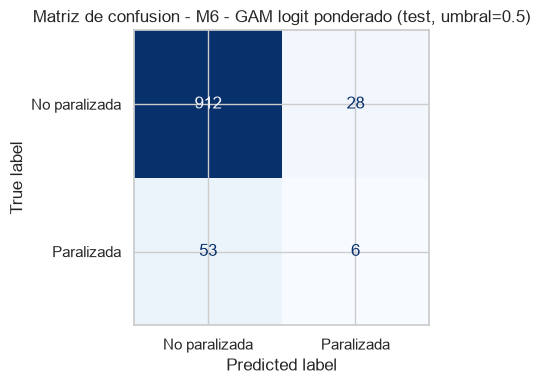

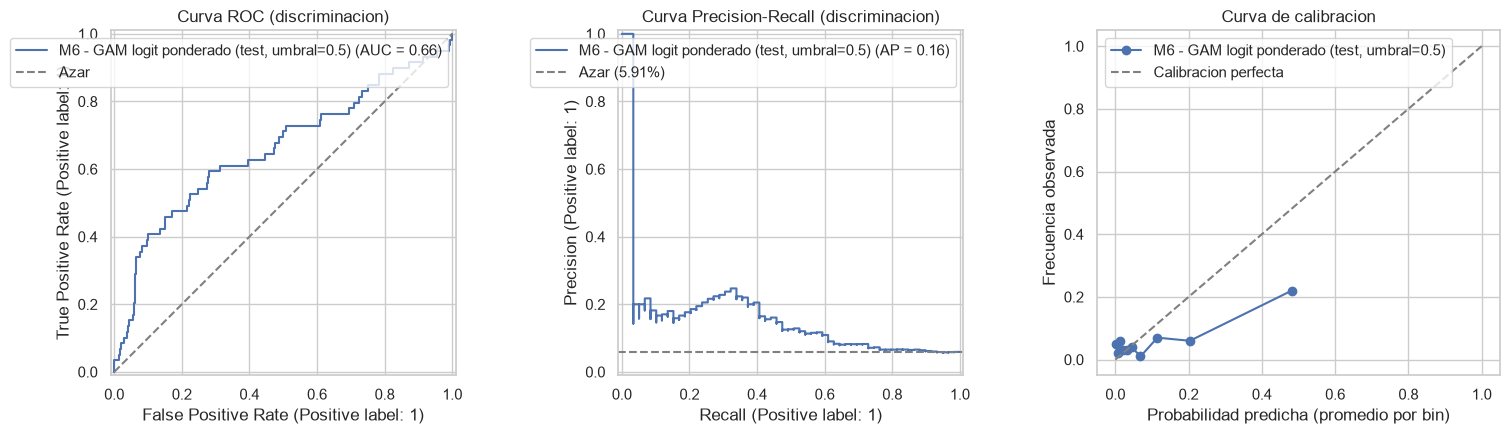

**Variables y peso - M6 - GAM logit ponderado** (`peso` = coeficiente para variables lineales/dummy; suma de |coeficientes de la base de splines| para variables suaves)

`odds_ratio = exp(coeficiente)`: cuanto se multiplican los momios (odds) de paralizacion por cada unidad de la variable, manteniendo lo demas constante. No aplica a los terminos suaves (spline).

| variable                                                           | tipo           |     peso |   p_valor |   odds_ratio |   abs_peso |
|:-------------------------------------------------------------------|:---------------|---------:|----------:|-------------:|-----------:|
| numeric_standard__n_obras_relacionadas_proyecto                    | suave (spline) |  14.8843 |  nan      |     nan      |    14.8843 |
| const                                                              | lineal         | -13.2723 |  nan      |       0      |    13.2723 |
| target_encoded__provincia_target_enc                               | suave (spline) |  11.9645 |  nan      |     nan      |    11.9645 |
| amount_log__monto_aprobado_soles_winsor_log                        | suave (spline) |   8.4393 |  nan      |     nan      |     8.4393 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   | lineal         |  -7.935  |    0.8962 |       0.0004 |     7.935  |
| woe__codigo_entidad_woe                                            | suave (spline) |   6.47   |  nan      |     nan      |     6.47   |
| numeric_standard__inco_2024_entidad                                | suave (spline) |   4.4706 |  nan      |     nan      |     4.4706 |
| numeric_standard__igeip_sector_ejecucion                           | suave (spline) |   3.7816 |  nan      |     nan      |     3.7816 |
| numeric_standard__igeip_sector                                     | suave (spline) |   3.7187 |  nan      |     nan      |     3.7187 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  | lineal         |  -3.1742 |    0.8834 |       0.0418 |     3.1742 |
| categorical__naturaleza_obra_Instalación                           | lineal         |  -2.9307 |    0.0192 |       0.0534 |     2.9307 |
| woe__sector_entidad_woe                                            | suave (spline) |   2.8281 |  nan      |     nan      |     2.8281 |
| numeric_standard__tasa_historica_movil_entidad                     | suave (spline) |   2.8048 |  nan      |     nan      |     2.8048 |
| target_encoded__departamento_target_enc                            | suave (spline) |   2.5814 |  nan      |     nan      |     2.5814 |
| target_encoded__tipo_obra_nivel_3_target_enc                       | suave (spline) |   1.911  |  nan      |     nan      |     1.911  |
| categorical__tipo_obra_nivel_1_Salud                               | lineal         |   1.5796 |    0.3135 |       4.853  |     1.5796 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento | lineal         |   1.3917 |    0.3438 |       4.0216 |     1.3917 |
| categorical__naturaleza_obra_Remodelación                          | lineal         |   1.3361 |    0.1031 |       3.8043 |     1.3361 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   | lineal         |   1.3333 |    0.3821 |       3.7935 |     1.3333 |
| target_encoded__tipo_obra_nivel_2_target_enc                       | suave (spline) |   1.3079 |  nan      |     nan      |     1.3079 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     | lineal         |   1.1688 |    0.3098 |       3.2182 |     1.1688 |
| categorical__naturaleza_obra_Rehabilitación                        | lineal         |   1.1105 |    0.1439 |       3.0359 |     1.1105 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              | lineal         |   1.0213 |    0.4824 |       2.7769 |     1.0213 |
| categorical__naturaleza_obra_Renovación                            | lineal         |   0.8816 |    0.268  |       2.4147 |     0.8816 |
| categorical__naturaleza_obra_Reconstrucción                        | lineal         |   0.7164 |    0.376  |       2.047  |     0.7164 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        | lineal         |   0.6471 |    0.5978 |       1.9099 |     0.6471 |
| categorical__naturaleza_obra_infrequent_sklearn                    | lineal         |   0.5624 |    0.6174 |       1.7549 |     0.5624 |
| categorical__tipo_formato_5.0                                      | lineal         |   0.2985 |    0.6447 |       1.3478 |     0.2985 |
| categorical__tipo_formato_2.0                                      | lineal         |   0.2421 |    0.6047 |       1.2739 |     0.2421 |
| categorical__naturaleza_obra_Mejoramiento                          | lineal         |  -0.1481 |    0.7992 |       0.8624 |     0.1481 |
| categorical__naturaleza_obra_Construcción/Creación                 | lineal         |  -0.0214 |    0.9741 |       0.9788 |     0.0214 |
| categorical__naturaleza_obra_Reparación                            | lineal         |   0.0142 |    0.9894 |       1.0143 |     0.0142 |

In [30]:
gam_m6 = GLMGam(
    y_train.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.Logit()),
    alpha=1.0,
)
result_m6 = gam_m6.fit(weights=pesos_balanceados_train, method="bfgs", maxiter=1000)

aic_m6, bic_m6 = calcular_aic_bic(result_m6.llf, len(result_m6.params), len(y_train))
print(f"AIC: {aic_m6:.2f} | BIC: {bic_m6:.2f} | Log-verosimilitud: {result_m6.llf:.2f}")

y_proba_m6 = np.asarray(result_m6.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m6 = (y_proba_m6 >= 0.5).astype(int)

metrics_m6 = reporte_evaluacion(
    y_test, y_pred_m6, y_proba_m6,
    nombre_modelo="M6 - GAM logit ponderado (test, umbral=0.5)"
)
importancia_m6 = importancia_gam_statsmodels(
    result_m6, columnas_lineales, columnas_suaves, bs_gam,
    nombre_modelo="M6 - GAM logit ponderado", enlace="logit"
)


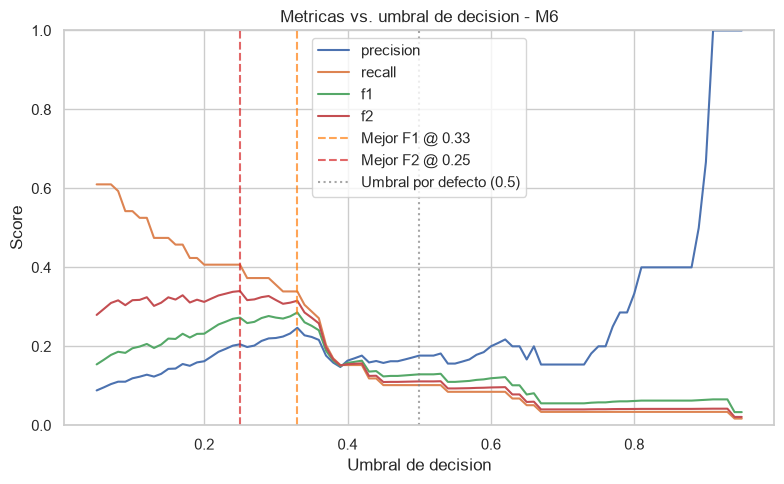

In [31]:
umbrales_m6 = analizar_umbrales(y_test, y_proba_m6)
mejor_f1_m6, mejor_f2_m6 = graficar_umbrales(umbrales_m6, nombre_modelo="M6")
UMBRAL_DECISION_M6 = mejor_f2_m6["umbral"]


##### M7: GAM con enlace c-loglog (ponderado)

c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\base\optimizer.py:634: FutureWarning: Keyword arguments have been passed to the optimizer that have no effect. The list of allowed keyword arguments for method bfgs is: gtol, norm, epsilon. The list of unsupported keyword arguments passed include: weights. After release 0.14, this will raise.
  check_kwargs(kwargs, ("gtol", "norm", "epsilon"), "bfgs")


AIC: 682.61 | BIC: 1049.47 | Log-verosimilitud: -273.30


**Metricas globales - M7 - GAM c-loglog ponderado (test, umbral=0.5)**

|             |   valor |
|:------------|--------:|
| roc_auc     |  0.6604 |
| pr_auc      |  0.1686 |
| gini        |  0.3207 |
| brier_score |  0.0673 |
| precision   |  0.1667 |
| recall      |  0.1017 |
| f1          |  0.1263 |
| f2          |  0.1103 |

**Reporte de clasificacion - M7 - GAM c-loglog ponderado (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.945 |    0.968 |      0.956 |   940     |
| 1            |       0.167 |    0.102 |      0.126 |    59     |
| accuracy     |       0.917 |    0.917 |      0.917 |     0.917 |
| macro avg    |       0.556 |    0.535 |      0.541 |   999     |
| weighted avg |       0.899 |    0.917 |      0.907 |   999     |

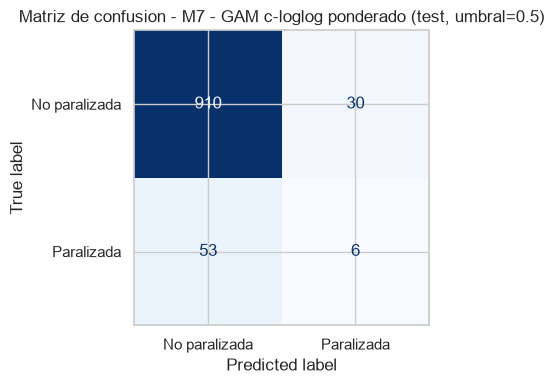

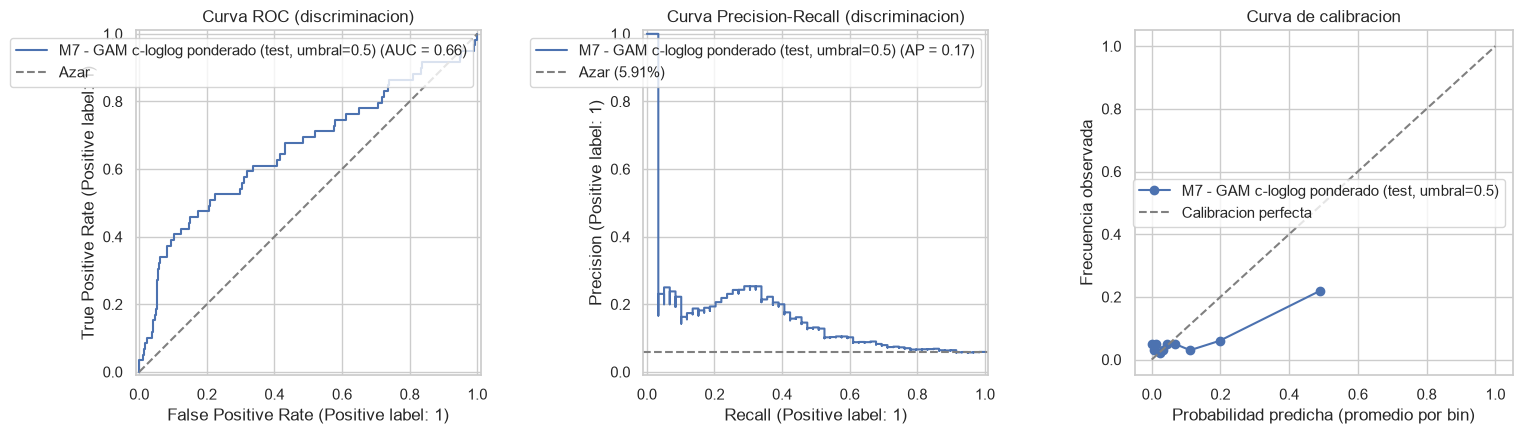

**Variables y peso - M7 - GAM c-loglog ponderado** (`peso` = coeficiente para variables lineales/dummy; suma de |coeficientes de la base de splines| para variables suaves)

`razon_riesgo = exp(coeficiente)`: bajo el enlace c-loglog (modelo de riesgos proporcionales en tiempo discreto), es la razon de riesgos (hazard ratio) de paralizacion por cada unidad de la variable. No aplica a los terminos suaves (spline).

| variable                                                           | tipo           |     peso |   p_valor |   razon_riesgo |   abs_peso |
|:-------------------------------------------------------------------|:---------------|---------:|----------:|---------------:|-----------:|
| numeric_standard__n_obras_relacionadas_proyecto                    | suave (spline) |  12.9808 |  nan      |       nan      |    12.9808 |
| const                                                              | lineal         | -12.1655 |    1      |         0      |    12.1655 |
| target_encoded__provincia_target_enc                               | suave (spline) |  10.4451 |  nan      |       nan      |    10.4451 |
| amount_log__monto_aprobado_soles_winsor_log                        | suave (spline) |   8.6712 |  nan      |       nan      |     8.6712 |
| numeric_standard__igeip_sector                                     | suave (spline) |   6.8865 |  nan      |       nan      |     6.8865 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   | lineal         |  -6.7961 |    0.8631 |         0.0011 |     6.7961 |
| woe__codigo_entidad_woe                                            | suave (spline) |   6.2457 |  nan      |       nan      |     6.2457 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  | lineal         |  -3.8672 |    0.8595 |         0.0209 |     3.8672 |
| numeric_standard__inco_2024_entidad                                | suave (spline) |   3.6404 |  nan      |       nan      |     3.6404 |
| categorical__naturaleza_obra_Instalación                           | lineal         |  -2.847  |    0.0156 |         0.058  |     2.847  |
| numeric_standard__tasa_historica_movil_entidad                     | suave (spline) |   2.2798 |  nan      |       nan      |     2.2798 |
| target_encoded__departamento_target_enc                            | suave (spline) |   2.1422 |  nan      |       nan      |     2.1422 |
| target_encoded__tipo_obra_nivel_2_target_enc                       | suave (spline) |   1.8618 |  nan      |       nan      |     1.8618 |
| target_encoded__tipo_obra_nivel_3_target_enc                       | suave (spline) |   1.7684 |  nan      |       nan      |     1.7684 |
| categorical__naturaleza_obra_Remodelación                          | lineal         |   1.2725 |    0.084  |         3.5698 |     1.2725 |
| woe__sector_entidad_woe                                            | suave (spline) |   1.2583 |  nan      |       nan      |     1.2583 |
| categorical__naturaleza_obra_Rehabilitación                        | lineal         |   1.0391 |    0.1142 |         2.8267 |     1.0391 |
| categorical__tipo_obra_nivel_1_Salud                               | lineal         |   0.8998 |    0.4821 |         2.4591 |     0.8998 |
| categorical__naturaleza_obra_Renovación                            | lineal         |   0.848  |    0.2261 |         2.3349 |     0.848  |
| categorical__naturaleza_obra_Reconstrucción                        | lineal         |   0.7471 |    0.2874 |         2.1108 |     0.7471 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   | lineal         |   0.7356 |    0.5304 |         2.0868 |     0.7356 |
| categorical__naturaleza_obra_infrequent_sklearn                    | lineal         |   0.6866 |    0.502  |         1.987  |     0.6866 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento | lineal         |   0.6673 |    0.5694 |         1.949  |     0.6673 |
| numeric_standard__igeip_sector_ejecucion                           | suave (spline) |   0.551  |  nan      |       nan      |     0.551  |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     | lineal         |   0.4988 |    0.5925 |         1.6467 |     0.4988 |
| categorical__tipo_formato_2.0                                      | lineal         |   0.2528 |    0.5593 |         1.2876 |     0.2528 |
| categorical__tipo_formato_5.0                                      | lineal         |   0.2055 |    0.7192 |         1.2282 |     0.2055 |
| categorical__naturaleza_obra_Reparación                            | lineal         |   0.1674 |    0.8607 |         1.1822 |     0.1674 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        | lineal         |   0.1143 |    0.9078 |         1.1211 |     0.1143 |
| categorical__naturaleza_obra_Construcción/Creación                 | lineal         |   0.0632 |    0.9129 |         1.0652 |     0.0632 |
| categorical__naturaleza_obra_Mejoramiento                          | lineal         |  -0.0391 |    0.9352 |         0.9617 |     0.0391 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              | lineal         |   0.0194 |    0.9848 |         1.0196 |     0.0194 |

In [32]:
gam_m7 = GLMGam(
    y_train.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
    alpha=1.0,
)
result_m7 = gam_m7.fit(weights=pesos_balanceados_train, method="bfgs", maxiter=1000)

aic_m7, bic_m7 = calcular_aic_bic(result_m7.llf, len(result_m7.params), len(y_train))
print(f"AIC: {aic_m7:.2f} | BIC: {bic_m7:.2f} | Log-verosimilitud: {result_m7.llf:.2f}")

y_proba_m7 = np.asarray(result_m7.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m7 = (y_proba_m7 >= 0.5).astype(int)

metrics_m7 = reporte_evaluacion(
    y_test, y_pred_m7, y_proba_m7,
    nombre_modelo="M7 - GAM c-loglog ponderado (test, umbral=0.5)"
)
importancia_m7 = importancia_gam_statsmodels(
    result_m7, columnas_lineales, columnas_suaves, bs_gam,
    nombre_modelo="M7 - GAM c-loglog ponderado", enlace="cloglog"
)


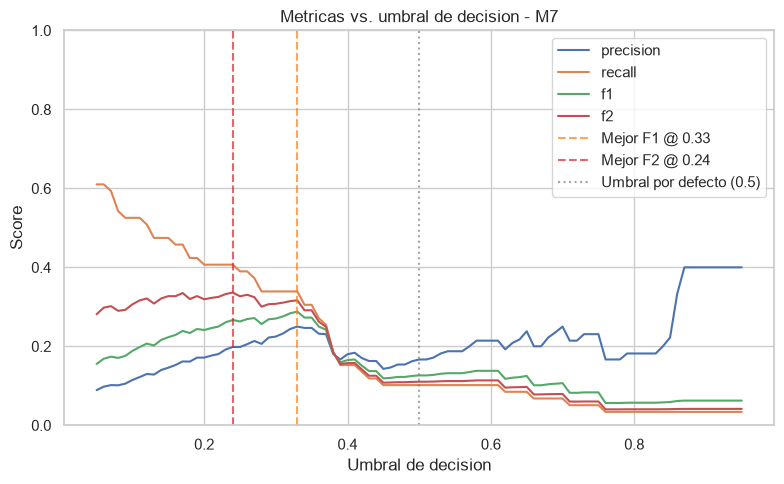

In [33]:
umbrales_m7 = analizar_umbrales(y_test, y_proba_m7)
mejor_f1_m7, mejor_f2_m7 = graficar_umbrales(umbrales_m7, nombre_modelo="M7")
UMBRAL_DECISION_M7 = mejor_f2_m7["umbral"]


##### M8: GAM con enlace probit (ponderado)

c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\base\optimizer.py:634: FutureWarning: Keyword arguments have been passed to the optimizer that have no effect. The list of allowed keyword arguments for method bfgs is: gtol, norm, epsilon. The list of unsupported keyword arguments passed include: weights. After release 0.14, this will raise.
  check_kwargs(kwargs, ("gtol", "norm", "epsilon"), "bfgs")


AIC: 683.31 | BIC: 1050.18 | Log-verosimilitud: -273.66


c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  rslt = super().fit(


**Metricas globales - M8 - GAM probit ponderado (test, umbral=0.5)**

|             |   valor |
|:------------|--------:|
| roc_auc     |  0.6525 |
| pr_auc      |  0.1557 |
| gini        |  0.3051 |
| brier_score |  0.0672 |
| precision   |  0.1212 |
| recall      |  0.0678 |
| f1          |  0.087  |
| f2          |  0.0743 |

**Reporte de clasificacion - M8 - GAM probit ponderado (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.943 |    0.969 |      0.956 |   940     |
| 1            |       0.121 |    0.068 |      0.087 |    59     |
| accuracy     |       0.916 |    0.916 |      0.916 |     0.916 |
| macro avg    |       0.532 |    0.518 |      0.521 |   999     |
| weighted avg |       0.895 |    0.916 |      0.905 |   999     |

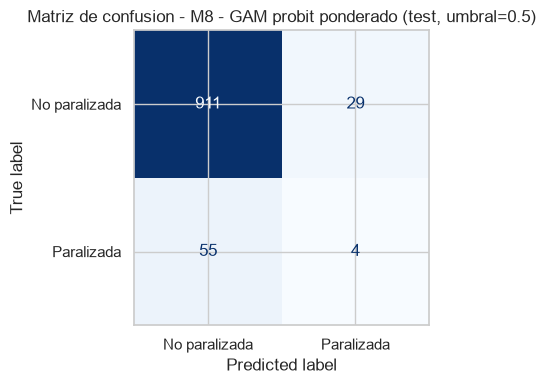

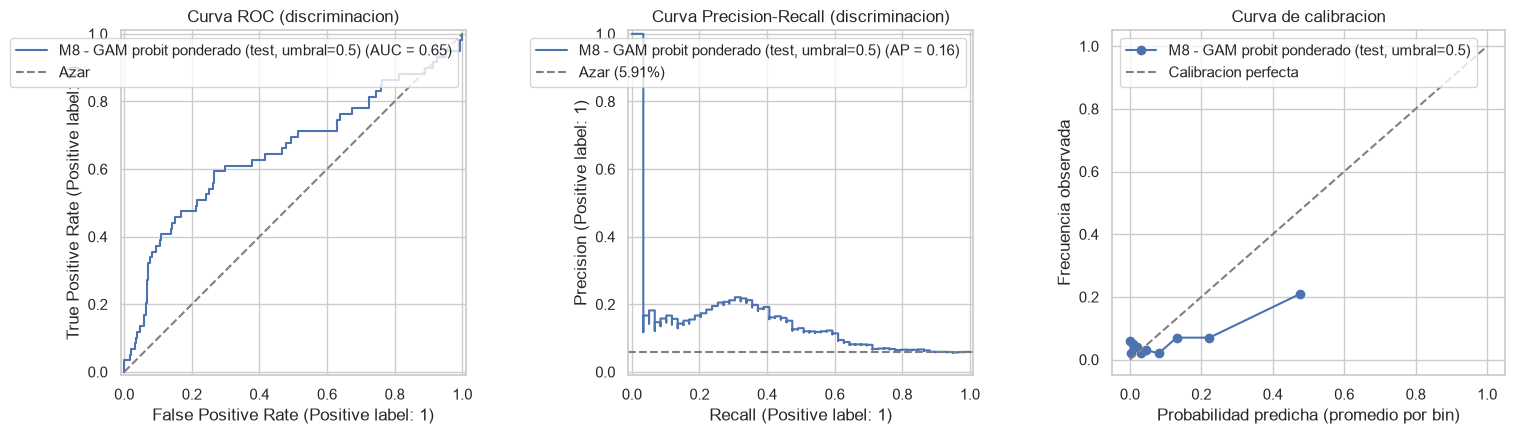

**Variables y peso - M8 - GAM probit ponderado** (`peso` = coeficiente para variables lineales/dummy; suma de |coeficientes de la base de splines| para variables suaves)

el enlace probit no tiene una interpretacion multiplicativa cerrada tipo odds/hazard ratio; `exp_coeficiente` se reporta solo como referencia. Para probit se suele interpretar el signo/magnitud relativa del coeficiente, o efectos marginales sobre la probabilidad. No aplica a los terminos suaves (spline).

| variable                                                           | tipo           |    peso |   p_valor |   exp_coeficiente |   abs_peso |
|:-------------------------------------------------------------------|:---------------|--------:|----------:|------------------:|-----------:|
| numeric_standard__n_obras_relacionadas_proyecto                    | suave (spline) |  7.6778 |  nan      |          nan      |     7.6778 |
| const                                                              | lineal         | -6.4843 |    1      |            0.0015 |     6.4843 |
| target_encoded__provincia_target_enc                               | suave (spline) |  5.777  |  nan      |          nan      |     5.777  |
| numeric_standard__igeip_sector_ejecucion                           | suave (spline) |  5.5434 |  nan      |          nan      |     5.5434 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   | lineal         | -4.3792 |    0.9768 |            0.0125 |     4.3792 |
| woe__codigo_entidad_woe                                            | suave (spline) |  3.2191 |  nan      |          nan      |     3.2191 |
| numeric_standard__inco_2024_entidad                                | suave (spline) |  3.1397 |  nan      |          nan      |     3.1397 |
| amount_log__monto_aprobado_soles_winsor_log                        | suave (spline) |  2.7325 |  nan      |          nan      |     2.7325 |
| woe__sector_entidad_woe                                            | suave (spline) |  2.7283 |  nan      |          nan      |     2.7283 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  | lineal         | -1.9045 |    0.9069 |            0.1489 |     1.9045 |
| target_encoded__tipo_obra_nivel_2_target_enc                       | suave (spline) |  1.6944 |  nan      |          nan      |     1.6944 |
| target_encoded__tipo_obra_nivel_3_target_enc                       | suave (spline) |  1.6742 |  nan      |          nan      |     1.6742 |
| numeric_standard__tasa_historica_movil_entidad                     | suave (spline) |  1.6514 |  nan      |          nan      |     1.6514 |
| categorical__naturaleza_obra_Instalación                           | lineal         | -1.267  |    0.0148 |            0.2817 |     1.267  |
| numeric_standard__igeip_sector                                     | suave (spline) |  1.2036 |  nan      |          nan      |     1.2036 |
| target_encoded__departamento_target_enc                            | suave (spline) |  1.1169 |  nan      |          nan      |     1.1169 |
| categorical__naturaleza_obra_Remodelación                          | lineal         |  0.7506 |    0.0803 |            2.1182 |     0.7506 |
| categorical__tipo_obra_nivel_1_Salud                               | lineal         |  0.7353 |    0.3901 |            2.0861 |     0.7353 |
| categorical__naturaleza_obra_Rehabilitación                        | lineal         |  0.622  |    0.1212 |            1.8627 |     0.622  |
| categorical__naturaleza_obra_Renovación                            | lineal         |  0.5728 |    0.1703 |            1.7733 |     0.5728 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento | lineal         |  0.497  |    0.529  |            1.6438 |     0.497  |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   | lineal         |  0.4051 |    0.6142 |            1.4994 |     0.4051 |
| categorical__naturaleza_obra_Reconstrucción                        | lineal         |  0.4009 |    0.348  |            1.4932 |     0.4009 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              | lineal         |  0.3154 |    0.6755 |            1.3707 |     0.3154 |
| categorical__naturaleza_obra_infrequent_sklearn                    | lineal         |  0.2102 |    0.72   |            1.2339 |     0.2102 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        | lineal         | -0.146  |    0.8378 |            0.8641 |     0.146  |
| categorical__naturaleza_obra_Mejoramiento                          | lineal         | -0.1151 |    0.7115 |            0.8913 |     0.1151 |
| categorical__naturaleza_obra_Reparación                            | lineal         |  0.102  |    0.856  |            1.1074 |     0.102  |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     | lineal         |  0.0901 |    0.8937 |            1.0943 |     0.0901 |
| categorical__tipo_formato_2.0                                      | lineal         |  0.0848 |    0.7261 |            1.0885 |     0.0848 |
| categorical__tipo_formato_5.0                                      | lineal         |  0.0251 |    0.9405 |            1.0254 |     0.0251 |
| categorical__naturaleza_obra_Construcción/Creación                 | lineal         |  0.01   |    0.9766 |            1.01   |     0.01   |

In [34]:
gam_m8 = GLMGam(
    y_train.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.Probit()),
    alpha=1.0,
)
result_m8 = gam_m8.fit(weights=pesos_balanceados_train, method="bfgs", maxiter=1000)

aic_m8, bic_m8 = calcular_aic_bic(result_m8.llf, len(result_m8.params), len(y_train))
print(f"AIC: {aic_m8:.2f} | BIC: {bic_m8:.2f} | Log-verosimilitud: {result_m8.llf:.2f}")

y_proba_m8 = np.asarray(result_m8.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m8 = (y_proba_m8 >= 0.5).astype(int)

metrics_m8 = reporte_evaluacion(
    y_test, y_pred_m8, y_proba_m8,
    nombre_modelo="M8 - GAM probit ponderado (test, umbral=0.5)"
)
importancia_m8 = importancia_gam_statsmodels(
    result_m8, columnas_lineales, columnas_suaves, bs_gam,
    nombre_modelo="M8 - GAM probit ponderado", enlace="probit"
)


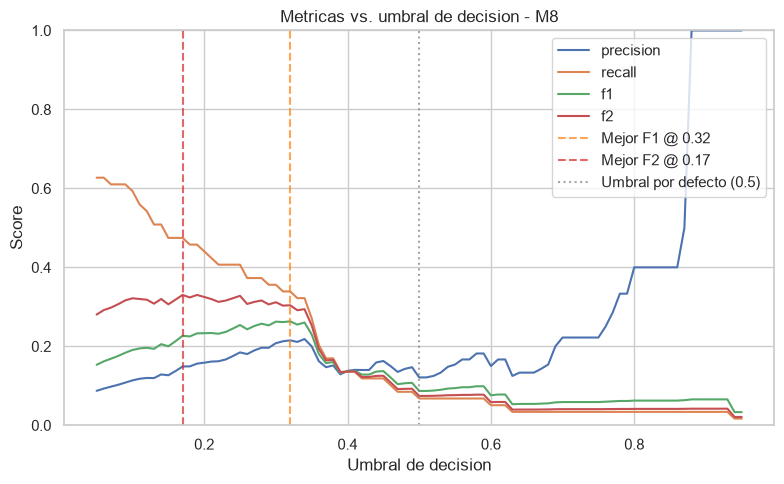

In [35]:
umbrales_m8 = analizar_umbrales(y_test, y_proba_m8)
mejor_f1_m8, mejor_f2_m8 = graficar_umbrales(umbrales_m8, nombre_modelo="M8")
UMBRAL_DECISION_M8 = mejor_f2_m8["umbral"]


### 5.4. Comparativa final (8 modelos)

**Metricas escogidas**: dado que el producto final del proyecto es una **probabilidad de riesgo** (`P(Y=1|X)`), no solo una clasificacion, la eleccion de metricas sigue tres dimensiones: **discriminacion** (ROC AUC, PR AUC -mas informativa que ROC AUC bajo fuerte desbalance de clases-, Gini `= 2*ROC AUC - 1`), **calibracion** (**Brier score**: `mean((p_hat - y)^2)`, menor es mejor; mide si la probabilidad predicha es una buena estimacion de la frecuencia real observada, no solo si ordena bien el riesgo) y **decision** a un umbral fijo (precision/recall/F1/F2; F2 pondera el recall el doble que la precision porque no detectar una obra que sí se va a paralizar -falso negativo- es mas costoso que investigar una que finalmente no se paraliza -falso positivo-). Se reportan a umbral=0.5 para comparar en igualdad de condiciones; la seccion anterior ya calculo, para cada modelo, el umbral que maximiza F2 (`UMBRAL_DECISION_*`). La seccion 5.5 profundiza en calibracion e interpretabilidad, que son igual de relevantes que el desempenio para elegir el modelo mas adecuado a este problema.

**Sobre la interpretabilidad**: cada GLM (M0, M4, M5) y M2 reportan su tabla de coeficientes + `exp(coeficiente)`, etiquetado segun la funcion de enlace (`odds_ratio` para logit, `razon_riesgo` -hazard ratio- para c-loglog; el enlace probit no tiene una interpretacion multiplicativa cerrada, se reporta solo como referencia). RF reporta importancia por impureza; los terminos suaves de M6/M7/M8 reportan una importancia agregada (no tienen un unico coeficiente interpretable); para M8 (enlace probit) el `exp(coeficiente)` de la parte lineal se reporta solo como referencia, sin interpretacion de tipo odds/hazard ratio (ver nota de M5).

In [36]:
comparativa_final = pd.DataFrame(
    [metrics_m0, metrics_m2, metrics_rf, metrics_m4, metrics_m5, metrics_m6, metrics_m7, metrics_m8],
    index=[
        "M0 - Regresion logistica base",
        "M2 - Regresion logistica (Elastic Net)",
        "RF - Random Forest",
        "M4 - GLM c-loglog ponderado",
        "M5 - GLM probit ponderado",
        "M6 - GAM logit ponderado",
        "M7 - GAM c-loglog ponderado",
        "M8 - GAM probit ponderado",
    ],
)
display(Markdown(comparativa_final.round(4).to_markdown()))


|                                        |   roc_auc |   pr_auc |   gini |   brier_score |   precision |   recall |     f1 |     f2 |
|:---------------------------------------|----------:|---------:|-------:|--------------:|------------:|---------:|-------:|-------:|
| M0 - Regresion logistica base          |    0.6888 |   0.1797 | 0.3777 |        0.0614 |      0.1923 |   0.0847 | 0.1176 | 0.0954 |
| M2 - Regresion logistica (Elastic Net) |    0.6609 |   0.1504 | 0.3218 |        0.2049 |      0.1065 |   0.5593 | 0.1789 | 0.3022 |
| RF - Random Forest                     |    0.6334 |   0.139  | 0.2668 |        0.1345 |      0.1405 |   0.4407 | 0.2131 | 0.3088 |
| M4 - GLM c-loglog ponderado            |    0.6861 |   0.1686 | 0.3723 |        0.1873 |      0.1314 |   0.6102 | 0.2162 | 0.3529 |
| M5 - GLM probit ponderado              |    0.6691 |   0.1541 | 0.3382 |        0.2028 |      0.1237 |   0.6271 | 0.2067 | 0.3458 |
| M6 - GAM logit ponderado               |    0.6589 |   0.1626 | 0.3179 |        0.0663 |      0.1765 |   0.1017 | 0.129  | 0.1111 |
| M7 - GAM c-loglog ponderado            |    0.6604 |   0.1686 | 0.3207 |        0.0673 |      0.1667 |   0.1017 | 0.1263 | 0.1103 |
| M8 - GAM probit ponderado              |    0.6525 |   0.1557 | 0.3051 |        0.0672 |      0.1212 |   0.0678 | 0.087  | 0.0743 |

In [37]:
comparativa_aic_bic = pd.DataFrame(
    {
        "M4 - GLM c-loglog ponderado": {"aic": aic_m4, "bic": bic_m4, "log_verosimilitud": result_m4.llf},
        "M5 - GLM probit ponderado": {"aic": aic_m5, "bic": bic_m5, "log_verosimilitud": result_m5.llf},
        "M6 - GAM logit ponderado": {"aic": aic_m6, "bic": bic_m6, "log_verosimilitud": result_m6.llf},
        "M7 - GAM c-loglog ponderado": {"aic": aic_m7, "bic": bic_m7, "log_verosimilitud": result_m7.llf},
        "M8 - GAM probit ponderado": {"aic": aic_m8, "bic": bic_m8, "log_verosimilitud": result_m8.llf},
    }
).T

display(Markdown("**AIC / BIC / log-verosimilitud (solo modelos GLM/GAM; M0/M2/RF no son comparables por esta via, M0 por usar una parametrizacion distinta -sin ponderar- y M2/RF por no ser modelos de maxima verosimilitud con la misma forma)**"))
display(comparativa_aic_bic.round(2))


**AIC / BIC / log-verosimilitud (solo modelos GLM/GAM; M0/M2/RF no son comparables por esta via, M0 por usar una parametrizacion distinta -sin ponderar- y M2/RF por no ser modelos de maxima verosimilitud con la misma forma)**

,aic,bic,log_verosimilitud
M4 - GLM c-loglog ponderado,1302.08,1474.73,-619.04
M5 - GLM probit ponderado,1308.89,1481.53,-622.44
M6 - GAM logit ponderado,690.66,1057.53,-277.33
M7 - GAM c-loglog ponderado,682.61,1049.47,-273.30
M8 - GAM probit ponderado,683.31,1050.18,-273.66


## 5.5. Calibracion, comparacion integral e interpretabilidad

Un modelo de riesgo con buena discriminacion puede, aun asi, entregar probabilidades poco confiables en terminos absolutos. Por ejemplo, dos modelos pueden ordenar igual de bien las obras de mayor a menor riesgo (ROC/PR AUC similares) pero uno puede sistematicamente sobre o sub-estimar la probabilidad real de paralizacion (peor Brier score, curva de calibracion alejada de la diagonal). Como el producto de este proyecto es precisamente esa probabilidad (`R(X) = P(Y=1|X)` como medida cuantitativa de riesgo, no solo una etiqueta 0/1), la calibracion se trata aqui como un criterio de seleccion tan relevante como el desempenio predictivo, y no como una verificacion posterior.

Se organiza la comparacion en las mismas 4 dimensiones: **discriminacion**, **calibracion**, **decision** e **interpretabilidad** (esta ultima inevitablemente cualitativa: existe un trade-off entre poder predictivo e interpretabilidad al pasar de una regresion logistica a un GAM o a un Random Forest).

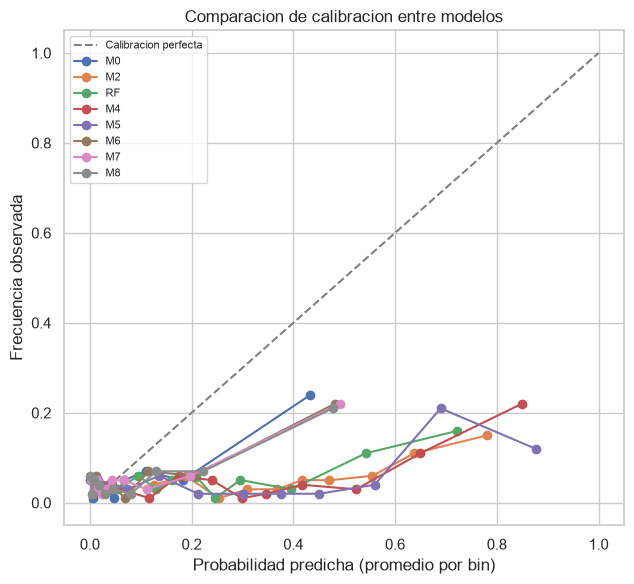

In [38]:
# Curvas de calibracion superpuestas (test) para los 8 modelos: permite ver, para
# probabilidades similares, que tan cerca esta cada modelo de la diagonal (calibracion
# perfecta), independientemente de su capacidad de discriminacion.
probas_test_por_modelo = {
    "M0": y_proba_m0,
    "M2": modelos_ajustados["M2 - Regresion logistica (Elastic Net)"].predict_proba(X_test)[:, 1],
    "RF": modelos_ajustados["RF - Random Forest"].predict_proba(X_test)[:, 1],
    "M4": y_proba_m4,
    "M5": y_proba_m5,
    "M6": y_proba_m6,
    "M7": y_proba_m7,
    "M8": y_proba_m8,
}

graficar_calibracion_comparativa(y_test, probas_test_por_modelo)


In [39]:
# El Brier score ya esta incluido en comparativa_final (seccion 5.4); se aisla aqui
# ordenado de mejor a peor para facilitar la lectura.
display(Markdown("**Ranking por Brier score (calibracion) - menor es mejor**"))
display(comparativa_final[["brier_score", "roc_auc", "pr_auc"]].sort_values("brier_score"))


**Ranking por Brier score (calibracion) - menor es mejor**

,brier_score,roc_auc,pr_auc
M0 - Regresion logistica base,0.061431,0.688839,0.179682
M6 - GAM logit ponderado,0.066337,0.658925,0.162645
M8 - GAM probit ponderado,0.067229,0.652542,0.155746
M7 - GAM c-loglog ponderado,0.067308,0.660368,0.168614
RF - Random Forest,0.134509,0.633393,0.138957
M4 - GLM c-loglog ponderado,0.187299,0.686134,0.168564
M5 - GLM probit ponderado,0.202806,0.669113,0.154086
M2 - Regresion logistica (Elastic Net),0.204943,0.660909,0.150358


### Tabla integral (discriminacion, calibracion, decision, interpretabilidad)

Las tres primeras columnas se derivan de `comparativa_final`; la interpretabilidad es una valoracion cualitativa: mayor cuando el modelo tiene coeficientes con una interpretacion directa y cerrada (odds ratio en logit), menor cuando requiere comparacion de escenarios (GAM) o solo importancia agregada sin signo/magnitud interpretable de forma aislada (Random Forest).

In [40]:
interpretabilidad_cualitativa = {
    "M0 - Regresion logistica base": "Alta (odds ratio directo, pero no ponderado/no converge con IRLS)",
    "M2 - Regresion logistica (Elastic Net)": "Alta (odds ratio directo)",
    "RF - Random Forest": "Baja (importancia global, sin signo ni odds ratio)",
    "M4 - GLM c-loglog ponderado": "Media (signo interpretable; exp(beta) es razon de riesgo, no odds ratio)",
    "M5 - GLM probit ponderado": "Media (signo interpretable; exp(beta) no tiene lectura multiplicativa cerrada)",
    "M6 - GAM logit ponderado": "Media-baja (terminos suaves: requieren comparacion de escenarios, no un unico coeficiente)",
    "M7 - GAM c-loglog ponderado": "Media-baja (idem M6, mas la salvedad del enlace c-loglog)",
    "M8 - GAM probit ponderado": "Media-baja (idem M6, mas la salvedad del enlace probit)",
}

tabla_integral = comparativa_final[["roc_auc", "pr_auc", "brier_score", "recall", "precision", "f2"]].copy()
tabla_integral["interpretabilidad"] = pd.Series(interpretabilidad_cualitativa)

display(Markdown("**Comparativa integral: discriminacion + calibracion + decision + interpretabilidad**"))
display(tabla_integral.round(4))


**Comparativa integral: discriminacion + calibracion + decision + interpretabilidad**

,roc_auc,pr_auc,brier_score,recall,precision,f2,interpretabilidad
M0 - Regresion logistica base,0.6888,0.1797,0.0614,0.0847,0.1923,0.0954,"Alta (odds ratio directo, pero no ponderado/no..."
M2 - Regresion logistica (Elastic Net),0.6609,0.1504,0.2049,0.5593,0.1065,0.3022,Alta (odds ratio directo)
RF - Random Forest,0.6334,0.1390,0.1345,0.4407,0.1405,0.3088,"Baja (importancia global, sin signo ni odds ra..."
M4 - GLM c-loglog ponderado,0.6861,0.1686,0.1873,0.6102,0.1314,0.3529,Media (signo interpretable; exp(beta) es razon...
M5 - GLM probit ponderado,0.6691,0.1541,0.2028,0.6271,0.1237,0.3458,Media (signo interpretable; exp(beta) no tiene...
M6 - GAM logit ponderado,0.6589,0.1626,0.0663,0.1017,0.1765,0.1111,Media-baja (terminos suaves: requieren compara...
M7 - GAM c-loglog ponderado,0.6604,0.1686,0.0673,0.1017,0.1667,0.1103,"Media-baja (idem M6, mas la salvedad del enlac..."
M8 - GAM probit ponderado,0.6525,0.1557,0.0672,0.0678,0.1212,0.0743,"Media-baja (idem M6, mas la salvedad del enlac..."


### Sobre la eleccion del "mejor" modelo

No se elige el modelo final solo por quien tiene mayor F2/PR-AUC. La tabla anterior deja ver un patron que vale la pena inspeccionar en cada corrida (los numeros exactos cambian con la particion de datos, pero el patron cualitativo es informativo): **los modelos ponderados por clase (`M2`, `M4`, `M5`) suelen tener el mejor recall/F2 pero el peor Brier score** — ponderar por clase corrige el umbral de decision a costa de distorsionar la calibracion (el peso artificial sobre la clase minoritaria hace que las probabilidades predichas dejen de ser una buena estimacion de la frecuencia real). `M0` (sin ponderar) suele tener el mejor Brier score mientras que casi nunca detecta una paralizacion al umbral 0.5: es el ejemplo mas puro de "bien calibrado pero inutil como clasificador al umbral por defecto". Los GAM ponderados (`M6`, `M7`, `M8`) suelen mantener un Brier score razonable pese a la ponderacion, lo que sugiere que su flexibilidad (splines) compensa parte de la distorsion que la ponderacion introduce en un modelo puramente lineal.

`RF` ilustra la otra cara de la disyuntiva: si discrimina mejor que un GLM/GAM pero tiene peor Brier score, ordena el riesgo un poco mejor pero sus probabilidades son menos confiables como estimacion cuantitativa de riesgo (que es, precisamente, el producto que este proyecto busca entregar) — ademas de ofrecer mucha menos interpretabilidad para explicar el porque detras de una obra clasificada como riesgo alto.

En consecuencia, la eleccion del modelo final depende de que se privilegie: si el objetivo es una **medida cuantitativa de riesgo confiable** (p. ej. para priorizar visitas de supervision proporcionalmente al riesgo), un modelo bien calibrado con buena interpretabilidad (M0, o un GAM ponderado si se necesita mejor recall) es preferible aunque pierda en las metricas de decision a umbral fijo; si el objetivo es **maximizar la deteccion de obras en riesgo bajo un presupuesto de falsos positivos aceptable**, un modelo ponderado (M2, M4) con el umbral ajustado (`UMBRAL_DECISION_*`) es mas adecuado, entendiendo que sus probabilidades ya no deben leerse literalmente como "la probabilidad real de paralizacion".

### Interpretacion de un GAM mediante comparacion de escenarios

Los terminos suaves de un GAM (`f_j(X_j)`) no tienen un unico coeficiente interpretable como un GLM lineal: el efecto de la variable depende de en que punto de su dominio se evalue. La forma correcta de interpretarlos es comparar la probabilidad predicha entre dos valores concretos de la variable, manteniendo todo lo demas constante — en vez de reportar un unico odds ratio global. A continuacion se hace esto para la variable suave con mayor peso agregado en M7 (ver `importancia_m7`, seccion 5.3).

In [41]:
top_suave_m7 = (
    importancia_m7[importancia_m7["tipo"] == "suave (spline)"]
    .sort_values("abs_peso", ascending=False)
    .iloc[0]["variable"]
)
idx_top_suave = columnas_suaves.index(top_suave_m7)

percentil_10 = np.quantile(X_smooth_train[:, idx_top_suave], 0.10)
percentil_90 = np.quantile(X_smooth_train[:, idx_top_suave], 0.90)

# Escenario base: todas las variables suaves en su promedio de train, parte lineal
# (dummies + constante) en su valor promedio de train (perfil "tipico").
smooth_base = X_smooth_train.mean(axis=0)
smooth_p10 = smooth_base.copy()
smooth_p10[idx_top_suave] = percentil_10
smooth_p90 = smooth_base.copy()
smooth_p90[idx_top_suave] = percentil_90

linear_promedio = X_linear_train_const.mean(axis=0, keepdims=True)

proba_p10, proba_p90 = np.asarray(result_m7.predict(
    exog=np.vstack([linear_promedio, linear_promedio]),
    exog_smooth=np.vstack([smooth_p10, smooth_p90]),
))

display(Markdown(
    f"**Escenario - M7**: manteniendo el resto de variables en su valor promedio de train, "
    f"al pasar `{top_suave_m7}` de su percentil 10 ({percentil_10:.3f}) a su percentil 90 "
    f"({percentil_90:.3f}), la probabilidad estimada de paralizacion pasa de "
    f"**{proba_p10:.3f}** a **{proba_p90:.3f}**."
))


**Escenario - M7**: manteniendo el resto de variables en su valor promedio de train, al pasar `numeric_standard__n_obras_relacionadas_proyecto` de su percentil 10 (-0.047) a su percentil 90 (-0.047), la probabilidad estimada de paralizacion pasa de **0.018** a **0.018**.

### Random Forest: importancia por permutacion (fuera de muestra)

La importancia por impureza (`importancia_rf`, seccion 5.2) se calcula durante el entrenamiento y esta sesgada hacia variables de alta cardinalidad/varianza. La importancia por permutacion mide, sobre **test** (fuera de muestra), cuanto empeora una metrica (PR AUC) al permutar aleatoriamente una variable — una medida mas confiable del aporte real de cada variable al desempenio del modelo.

In [42]:
from sklearn.inspection import permutation_importance

modelo_rf_ajustado = modelos_ajustados["RF - Random Forest"]
resultado_permutacion = permutation_importance(
    modelo_rf_ajustado, X_test, y_test,
    scoring="average_precision", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)

tabla_permutacion_rf = pd.DataFrame({
    "variable": X_test.columns,
    "importancia_permutacion_media": resultado_permutacion.importances_mean,
    "std": resultado_permutacion.importances_std,
}).sort_values("importancia_permutacion_media", ascending=False).reset_index(drop=True)

display(Markdown("**Importancia por permutacion (PR-AUC, test) - RF**"))
display(tabla_permutacion_rf.round(4))


**Importancia por permutacion (PR-AUC, test) - RF**

,variable,importancia_permutacion_media,std
0,naturaleza_obra,0.0398,0.0049
1,tipo_formato,0.0202,0.0156
2,monto_aprobado_soles,0.0181,0.0203
3,codigo_entidad,0.0169,0.0178
4,departamento,0.0041,0.0085
5,n_obras_relacionadas_proyecto,0.0000,0.0000
6,tasa_historica_movil_entidad,-0.0009,0.0118
7,inco_2024_entidad,-0.0017,0.0097
8,tipo_obra_nivel_2,-0.0039,0.0079
9,igeip_sector,-0.0071,0.0050


## 6. Reproducibilidad

- Semilla unica `RANDOM_STATE = 42` reutilizada en todos los estimadores con componente aleatoria.
- Fuente de datos materializada en `data/gold/ds_op_inco_igeip.csv` (no depende de una conexion a base de datos en vivo).
- Particion train/test y validacion cruzada (`TimeSeriesSplit`) deterministas por orden temporal, sin shuffle.
- Todo el preprocesamiento (winsorizacion+log, estandarizacion, imputacion por mediana, target encoding, WOE, one-hot) vive dentro de un unico `Pipeline`/`ColumnTransformer` de scikit-learn (`src/features/preprocessing.py`), ajustado exclusivamente con datos de entrenamiento en cada fold/particion — evita fuga de datos y hace que `fit`/`predict` sean reproducibles de punta a punta.
- El desbalance de clases se trata con pesos de caso (ponderacion en la funcion de verosimilitud), no con sobre/sub-muestreo, preservando la interpretacion de coeficientes/odds ratio de los modelos GLM.
- Funciones reutilizables (encoders, pipelines, metricas, graficos de umbral, tablas de importancia) centralizadas en `src/features/` y `src/evaluation/`, sin logica duplicada entre notebooks.